# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

RAW_CLIENTS = "clients.csv"
RAW_TXN = "transactions.csv"

In [3]:
def share(n, total):
    p = n / total
    return f"{n:,} из {total:,} ({p:.2%})" if p >= 0.01 else f"{n:,} из {total:,} ({p:.3%})"

audit_notes = [] #журнал
def note(field, issue, scope, n_rows, value_before, plan, why=""):
    audit_notes.append(dict(field=field, issue=issue, scope=scope, n_rows=n_rows,
                            value_before=value_before, planned_action=plan, rationale=why))

log_rows = []
def log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    log_rows[:] = [r for r in log_rows if (r["field"], r["issue"]) != (field, issue)]
    log_rows.append(dict(field=field, issue=issue, scope=scope, n_rows=n_rows,
                         value_before=value_before, action=action,
                         value_after=value_after, rationale=rationale))

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

Тут определяем кодировки для файлов, также когда сам файл в некоторой кодировке прочитался без ошибок, то я вывожу кусок текста чтобы убедится что действительно русский язык прочтен верно, также там можно посмотреть на разделители, что я дополнительно отобразил выводя коичество запятых и точек с запятой.

**У таблицы клиентов определена кодировка utf-8, разделители - запятые**
**У таблицы операций определена кодировка cp1251, разделители - точки с запятой**

In [4]:
for path in (RAW_CLIENTS, RAW_TXN):
    raw_bytes = open(path, "rb").read()
    first_line = raw_bytes.split(b"\n")[0]
    print(path, "| размер:", f"{len(raw_bytes) / 2**20:.1f} МБ")
    for enc in ("utf-8", "cp1251"):
        try:
            text = raw_bytes.decode(enc)
            raw_bytes.decode(enc)
            print(f"  {enc:7s}: читается без ошибок || {text.split(chr(10))[1][:60]}")
        except UnicodeDecodeError as e:
            print(f"  {enc:7s}: ОШИБКА на байте {e.start}")
    print("  в заголовке запятых:", first_line.count(b","), "| точек с запятой:", first_line.count(b";"))

with open(RAW_TXN, encoding="cp1251") as f:
    for _ in range(3):
        print(repr(f.readline()))

clients.csv | размер: 1.0 МБ
  utf-8  : читается без ошибок || C004875,1975-07-19,М,Санкт-Петербург,Массовый,Серебро,Дебето
  cp1251 : ОШИБКА на байте 4485
  в заголовке запятых: 15 | точек с запятой: 0
transactions.csv | размер: 46.0 МБ
  utf-8  : ОШИБКА на байте 125
  cp1251 : читается без ошибок || 990199;C002747;2023-12-01 17:38:32;547,62;RUB;Продукты;5411;
  в заголовке запятых: 0 | точек с запятой: 8
'txn_id;client_id;txn_datetime;amount;currency;category;mcc_code;channel;status\n'
'990199;C002747;2023-12-01 17:38:32;547,62;RUB;Продукты;5411;Онлайн-банк;успешно\n'
'990111;C004838;2023-12-02 11:55:35;2210,49;RUB;АЗС;5541;Токен;успешно\n'


In [5]:
clients_raw = pd.read_csv(RAW_CLIENTS, dtype=str, keep_default_na=False, encoding="utf-8")
tx_raw = pd.read_csv(RAW_TXN, sep=";", encoding="cp1251", dtype=str, keep_default_na=False)


print("clients_raw:", clients_raw.shape)
print("tx_raw     :", tx_raw.shape)
clients_raw.sample(3, random_state=1)

clients = clients_raw.copy()
tx = tx_raw.copy()

clients_raw: (5694, 16)
tx_raw     : (623808, 9)


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

Заранее определим знаменатели

In [6]:
N = {
    "clients_rows":   len(clients_raw),
    "clients_ids":    clients_raw.client_id.nunique(),
    "clients_income": int(clients.monthly_income.notna().sum()),
    "tx_rows":        len(tx_raw),
    "tx_clients":     tx_raw.client_id.nunique(),
    "tx_azs":         int((tx_raw.category == "АЗС").sum()),
}

### 2.1. Объём, типы, ключи, единица наблюдения

In [7]:
def overview(raw, typed, name):
    out = pd.DataFrame({
        "тип": typed.dtypes.astype(str),
        "уникальных": raw.nunique(),
        "пустых": (raw == "").sum(),
        "пустых, %": ((raw == "").mean() * 100).round(2),
        "пример": raw.iloc[0],
    })
    print(f"{name}: {raw.shape[0]:,} строк x {raw.shape[1]} столбцов")
    return out

display(overview(clients_raw, clients, "clients"))
display(overview(tx_raw, tx[tx_raw.columns], "transactions"))

clients: 5,694 строк x 16 столбцов


,тип,уникальных,пустых,"пустых, %",пример
client_id,str,5639,0,0.00,C004875
birth_date,str,4802,0,0.00,1975-07-19
gender,str,2,0,0.00,М
city,str,17,0,0.00,Санкт-Петербург
segment,str,4,0,0.00,Массовый
loyalty_tier,str,4,0,0.00,Серебро
card_type,str,3,0,0.00,Дебетовая
registration_date,str,3242,0,0.00,19.12.2016
card_open_date,str,2635,0,0.00,20.12.2021
income_source,str,3,0,0.00,Зарплата в другом банке


transactions: 623,808 строк x 9 столбцов


,тип,уникальных,пустых,"пустых, %",пример
txn_id,str,622308,0,0.0,990199
client_id,str,5994,0,0.0,C002747
txn_datetime,str,567001,0,0.0,2023-12-01 17:38:32
amount,str,322906,0,0.0,"547,62"
currency,str,3,0,0.0,RUB
category,str,12,0,0.0,Продукты
mcc_code,str,9,0,0.0,5411
channel,str,4,0,0.0,Онлайн-банк
status,str,3,0,0.0,успешно


In [8]:
clients.info()

<class 'pandas.DataFrame'>
RangeIndex: 5694 entries, 0 to 5693
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   client_id           5694 non-null   str  
 1   birth_date          5694 non-null   str  
 2   gender              5694 non-null   str  
 3   city                5694 non-null   str  
 4   segment             5694 non-null   str  
 5   loyalty_tier        5694 non-null   str  
 6   card_type           5694 non-null   str  
 7   registration_date   5694 non-null   str  
 8   card_open_date      5694 non-null   str  
 9   income_source       5694 non-null   str  
 10  monthly_income      5694 non-null   str  
 11  has_mobile_app      5694 non-null   str  
 12  app_last_login      5694 non-null   str  
 13  satisfaction_score  5694 non-null   str  
 14  branch_code         5694 non-null   str  
 15  marketing_opt_in    5694 non-null   str  
dtypes: str(16)
memory usage: 1.6 MB


In [9]:
tx.info()

<class 'pandas.DataFrame'>
RangeIndex: 623808 entries, 0 to 623807
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   txn_id        623808 non-null  str  
 1   client_id     623808 non-null  str  
 2   txn_datetime  623808 non-null  str  
 3   amount        623808 non-null  str  
 4   currency      623808 non-null  str  
 5   category      623808 non-null  str  
 6   mcc_code      623808 non-null  str  
 7   channel       623808 non-null  str  
 8   status        623808 non-null  str  
dtypes: str(9)
memory usage: 96.9 MB


In [10]:
n_cl, n_cl_u = len(clients_raw), clients_raw.client_id.nunique()
n_tx, n_tx_u = len(tx_raw), tx_raw.txn_id.nunique()
print(f"clients     : строк {n_cl:,}, уникальных client_id {n_cl_u:,} -> лишних строк {n_cl - n_cl_u}")
print(f"transactions: строк {n_tx:,}, уникальных txn_id    {n_tx_u:,} -> лишних строк {n_tx - n_tx_u}")
print(f"клиентов в операциях: {tx_raw.client_id.nunique():,}; операций на клиента (медиана): "
      f"{tx_raw.groupby('client_id').size().median():.0f}")

clients     : строк 5,694, уникальных client_id 5,639 -> лишних строк 55
transactions: строк 623,808, уникальных txn_id    622,308 -> лишних строк 1500
клиентов в операциях: 5,994; операций на клиента (медиана): 90


### 2.2. Дубли

Отсюда видно, что у нас в таблице клиентов есть полные дубли строк, 40 штук, также есть 15 клиентов с одинаковыми id, но у которых отличаются поля city и/или segment, если первая проблема решается по сути удалением копии, то у второй придется решить правило выбора версии

In [11]:
full_dup_cl = clients_raw.duplicated(keep=False)
key_dup_cl = clients_raw.client_id.duplicated(keep=False)
ids_key = clients_raw.loc[key_dup_cl, "client_id"].nunique()
ids_full = clients_raw.loc[full_dup_cl, "client_id"].nunique()
print("Полных дублей (лишних строк):", clients_raw.duplicated().sum())
print(f"client_id, встречающихся >1 раза: {ids_key}  (из них полностью одинаковые строки: {ids_full})")

conf = clients_raw[key_dup_cl & ~full_dup_cl]
conf_ids = conf.client_id.unique()
diff_fields = conf.groupby("client_id").nunique().gt(1).sum()
print(f"\nКонфликтующих client_id: {len(conf_ids)} ({2 * len(conf_ids)} строк); расходятся поля:")
print(diff_fields[diff_fields > 0].to_string())
display(conf.sort_values("client_id").head(30)[["client_id", "city", "segment", "loyalty_tier", "card_type", "registration_date"]])

Полных дублей (лишних строк): 40
client_id, встречающихся >1 раза: 55  (из них полностью одинаковые строки: 40)

Конфликтующих client_id: 15 (30 строк); расходятся поля:
city       15
segment    11


,client_id,city,segment,loyalty_tier,card_type,registration_date
989,C001562,Казань,Массовый,Базовый,Дебетовая,08.03.2020
2729,C001562,Екатеринбург,Зарплатный,Базовый,Дебетовая,08.03.2020
170,C001965,Нижний Новгород,Массовый,Базовый,Дебетовая,15.10.2021
5544,C001965,Москва,Private,Базовый,Дебетовая,15.10.2021
236,C002104,г. Новосибирск,Зарплатный,Базовый,Кредитная,08.11.2013
4366,C002104,Екатеринбург,Зарплатный,Базовый,Кредитная,08.11.2013
3769,C002442,Санкт-Петербург,Премиальный,Серебро,Дебетовая,17.12.2016
4900,C002442,Казань,Private,Серебро,Дебетовая,17.12.2016
4687,C002671,Нижний Новгород,Зарплатный,Базовый,Дебетовая,08.02.2019
5086,C002671,Екатеринбург,Массовый,Базовый,Дебетовая,08.02.2019


Здесь можно увидеть похожую ситуацию в таблице транзакций, 1291 точная копия строк, что опять же решается удалением копии и 209 строк так же копий, но у которых уточнено время, тут нажо оставить версию с временем, по логике это одна и та же транзакция.

In [12]:
tx_dup_mask = tx_raw.txn_id.duplicated(keep=False)
dup_ids = tx_raw.loc[tx_dup_mask, "txn_id"].unique()
print("Полных дублей (лишних строк):", tx_raw.duplicated().sum())
print("txn_id, встречающихся >1 раза:", len(dup_ids))


sub = tx_raw[tx_dup_mask].assign(txn_date=lambda d: d.txn_datetime.str[:10])
n_var = sub.groupby("txn_id").nunique()
other = [c for c in tx_raw.columns if c not in ("txn_id", "txn_datetime")]
others_same = n_var[other].le(1).all(axis=1)
kind = np.select(
    [(n_var.txn_datetime == 1) & others_same,
     (n_var.txn_datetime > 1) & (n_var.txn_date == 1) & others_same],
    ["точная копия", "то же, но у одной копии нет времени (только дата)"],
    default="разное содержимое")
kinds = pd.Series(kind, index=n_var.index).value_counts()
print("\nТипы повторов txn_id:")
print(kinds.to_string())

content_cols = [c for c in tx_raw.columns if c != "txn_id"]
print("\nДублей по содержанию при другом txn_id:", tx_raw.duplicated(subset=content_cols).sum()
      - tx_raw.duplicated().sum())




Полных дублей (лишних строк): 1291
txn_id, встречающихся >1 раза: 1500

Типы повторов txn_id:
точная копия                                         1291
то же, но у одной копии нет времени (только дата)     209

Дублей по содержанию при другом txn_id: 0


### 2.3. Соответствие данных описанию полей из задания

Тут видно, что вместо ожидаемых 6 написаний городов встречается 17 с разными регистрами, припиской г. или сокращений в случае Cанкт-Петербурга и Нмжнего Новгорода. Надо приводить к единому написанию. Так же и вместо 9 ожидаемых категорий встречается 12, решается по сути так же приведением к 9 каноническим названиям.

In [13]:
EXPECTED = {
    "gender": {"М", "Ж"},
    "segment": {"Массовый", "Зарплатный", "Премиальный", "Private"},
    "loyalty_tier": {"Базовый", "Серебро", "Золото", "Платина"},
    "card_type": {"Дебетовая", "Кредитная", "Премиальная"},
    "has_mobile_app": {"Да", "Нет"},
    "marketing_opt_in": {"Да", "Нет"},
    "income_source": {"Зарплата в нашем банке", "Зарплата в другом банке", "Не указан"},
}
CITIES = {"Москва", "Санкт-Петербург", "Новосибирск", "Нижний Новгород", "Казань", "Екатеринбург"}
CATEGORIES = {"Продукты", "Транспорт", "Одежда и обувь", "АЗС", "Кафе и рестораны",
              "Развлечения и досуг", "Аптеки", "Онлайн-сервисы", "Связь и интернет"}

rows = []
for col, allowed in EXPECTED.items():
    bad = ~clients_raw[col].isin(allowed)
    rows.append((f"clients.{col}", len(allowed), clients_raw[col].nunique(), int(bad.sum())))
bad_city = ~clients_raw.city.isin(CITIES)
rows.append(("clients.city", len(CITIES), clients_raw.city.nunique(), int(bad_city.sum())))
for col, allowed in {"currency": {"RUB", "EUR", "USD"}, "channel": {"Карта", "Токен", "СБП", "Онлайн-банк"},
                     "status": {"успешно", "отклонено", "возврат"}}.items():
    rows.append((f"tx.{col}", len(allowed), tx_raw[col].nunique(), int((~tx_raw[col].isin(allowed)).sum())))
bad_cat = ~tx_raw.category.isin(CATEGORIES)
rows.append(("tx.category", len(CATEGORIES), tx_raw.category.nunique(), int(bad_cat.sum())))
display(pd.DataFrame(rows, columns=["поле", "должно быть значений", "фактически", "строк с недопустимым"]))

print("Написания города:"); display(clients_raw.city.map(repr).value_counts().to_frame("строк"))
print("Написания категории:"); display(tx_raw.category.value_counts().to_frame("операций"))

print(tx_raw.category.nunique())




,поле,должно быть значений,фактически,строк с недопустимым
0,clients.gender,2,2,0
1,clients.segment,4,4,0
2,clients.loyalty_tier,4,4,0
3,clients.card_type,3,3,0
4,clients.has_mobile_app,2,2,0
5,clients.marketing_opt_in,2,2,0
6,clients.income_source,3,3,0
7,clients.city,6,17,1671
8,tx.currency,3,3,0
9,tx.channel,4,4,0


Написания города:


,строк
city,
'Москва',1105
'Нижний Новгород',706
'Санкт-Петербург',670
'Казань',527
'Екатеринбург',510
'Новосибирск',505
'Н. Новгород',237
'г. Москва',201
' москва',181


Написания категории:


,операций
category,
Продукты,164675
Транспорт,65908
Одежда и обувь,64664
АЗС,57997
Кафе и рестораны,50642
Развлечения и досуг,47491
Аптеки,45417
Онлайн-сервисы,44016
Связь и интернет,29143


12


В описании задания закзчик сообщает, что МСС соответсвует категории покупки, что не сходится в реальности, необходимо будет решить на что смотреть, категорию или МСС.

In [14]:
MCC_TO_CAT = {"5411": "Продукты", "4111": "Транспорт", "5651": "Одежда и обувь", "5541": "АЗС",
              "5812": "Кафе и рестораны", "7832": "Развлечения и досуг", "5912": "Аптеки",
              "5815": "Онлайн-сервисы", "4814": "Связь и интернет"}

cat_key = tx_raw.category.str.lower().str.replace("/", " и ", regex=False)
exp_key = tx_raw.mcc_code.map(MCC_TO_CAT).str.lower()
mcc_unknown = exp_key.isna()
mcc_mismatch = ~mcc_unknown & (cat_key != exp_key)
print("MCC вне справочника:", share(int(mcc_unknown.sum()),(N["tx_rows"])))
print("MCC не совпадает с категорией:", share(int(mcc_mismatch.sum()),N["tx_rows"]))
display(tx_raw[mcc_mismatch].category.value_counts().head(9).to_frame("несовпадений"))


MCC вне справочника: 0 из 623,808 (0.000%)
MCC не совпадает с категорией: 1,624 из 623,808 (0.260%)


,несовпадений
category,
Продукты,429
Одежда и обувь,191
Транспорт,167
АЗС,134
Онлайн-сервисы,133
Кафе и рестораны,121
Развлечения и досуг,119
Аптеки,119
Связь и интернет,70


In [15]:
def to_dt(s, fmt):
    return pd.to_datetime(s.where(s != ""), format=fmt, errors="coerce")

def to_num(s):
    return pd.to_numeric(s.where(s != "").str.replace(",", ".", regex=False), errors="coerce")

clients_t = clients_raw.assign(
    birth_date=to_dt(clients_raw.birth_date, "%Y-%m-%d"),
    registration_date=to_dt(clients_raw.registration_date, "%d.%m.%Y"),
    card_open_date=to_dt(clients_raw.card_open_date, "%d.%m.%Y"),
    app_last_login=to_dt(clients_raw.app_last_login, "%Y-%m"),
    monthly_income=to_num(clients_raw.monthly_income),
    satisfaction_score=to_num(clients_raw.satisfaction_score),
)

t_full = pd.to_datetime(tx_raw.txn_datetime, format="%Y-%m-%d %H:%M:%S", errors="coerce")
t_date = pd.to_datetime(tx_raw.txn_datetime, format="%Y-%m-%d", errors="coerce")
tx_t = tx_raw.assign(
    txn_dt=t_full.fillna(t_date),
    has_time=tx_raw.txn_datetime.str.len() > 10,
    amount=to_num(tx_raw.amount),
)


Тут можно заметить, что в таблице есть 33 клиента с датой регистрации меньше 18 лет, также в колонке monthly_income у 48 клиентов стоит -999, вероятно это значение используется как заглушка, нужно будет в дальнейшем решить заполнять ее или сделать пропуском.

In [16]:
DATA_START = pd.Timestamp("2024-01-01")
BASE_END   = pd.Timestamp("2024-12-31")
EVAL_START = pd.Timestamp("2025-01-01")
DATA_END   = pd.Timestamp("2025-06-30")
age = (DATA_END - clients_t.birth_date).dt.days / 365.25
reg18 = clients_t.registration_date < clients_t.birth_date + pd.DateOffset(years=18)
logic = pd.Series({
    "возраст < 18 или > 100 лет": int(((age < 18) | (age > 100)).sum()),
    "дата рождения/регистрации/открытия карты позже 30.06.2025": int(((clients_t.birth_date > DATA_END)
        | (clients_t.registration_date > DATA_END) | (clients_t.card_open_date > DATA_END)).sum()),
    "карта открыта раньше прихода в банк": int((clients_t.card_open_date < clients_t.registration_date).sum()),
    "приход в банк до 18-летия": int(reg18.sum()),
    "has_mobile_app=Да, но нет месяца входа": int(((clients_raw.has_mobile_app == "Да") & clients_t.app_last_login.isna()).sum()),
    "has_mobile_app=Нет, но месяц входа есть": int(((clients_raw.has_mobile_app == "Нет") & clients_t.app_last_login.notna()).sum()),
    "последний вход позже 2025-06": int((clients_t.app_last_login > DATA_END).sum()),
    "satisfaction_score вне 1..5": int((~clients_t.satisfaction_score.dropna().between(1, 5)).sum()),
    "monthly_income <= 0": int((clients_t.monthly_income <= 0).sum()),
}, name=f"клиентов (из {len(clients_raw):,})")
display(logic.to_frame())
print("Значения monthly_income <= 0:", clients_t.loc[clients_t.monthly_income <= 0, "monthly_income"].unique())
print("Возраст на 30.06.2025:", age.min().round(1), "-", age.max().round(1))

,"клиентов (из 5,694)"
возраст < 18 или > 100 лет,0
дата рождения/регистрации/открытия карты позже 30.06.2025,0
карта открыта раньше прихода в банк,0
приход в банк до 18-летия,33
"has_mobile_app=Да, но нет месяца входа",0
"has_mobile_app=Нет, но месяц входа есть",0
последний вход позже 2025-06,0
satisfaction_score вне 1..5,0
monthly_income <= 0,48


Значения monthly_income <= 0: [-999.]
Возраст на 30.06.2025: 22.5 - 88.9


Здесь найдено 92 операции вне заявленного периода, их придется убрать, также есть операции которые проводятся не в рублях, но курса для пересчета у нас нет, поэтому эти операции придется убрать.

In [17]:
dt = tx_t.txn_dt
out_before = dt < DATA_START
out_after = dt > DATA_END + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
print("Операции ДО 2024-01-01:", share(int(out_before.sum()),len(tx_t)), "| от", dt[out_before].min(), "до", dt[out_before].max())
print("Операции ПОСЛЕ 2025-06-30:", share(int(out_after.sum()),len(tx_t)), "| от", dt[out_after].min(), "до", dt[out_after].max())

display(tx_t.groupby("status").amount.agg(n="size", min="min", median="median", max="max",
        neg=lambda s: int((s < 0).sum())).round(2))

display(tx_t.groupby("currency").amount.agg(n="size", median="median").round(2))
print("Доля нерублёвых операций:", share(int((tx_raw.currency != "RUB").sum()),len(tx_t)))

Операции ДО 2024-01-01: 10 из 623,808 (0.002%) | от 2023-12-01 17:38:32 до 2023-12-31 12:02:26
Операции ПОСЛЕ 2025-06-30: 82 из 623,808 (0.013%) | от 2025-07-02 00:00:00 до 2026-07-21 07:20:02


,n,min,median,max,neg
status,,,,,
возврат,7496,-46390.16,-1058.70,-0.35,7496
отклонено,12507,0.49,1731.20,61449.62,0
успешно,603805,0.12,1066.39,121692.01,0


,n,median
currency,,
EUR,1250,10.79
RUB,621348,1063.39
USD,1210,11.23


Доля нерублёвых операций: 2,460 из 623,808 (0.394%)


### 2.4. Связь между таблицами

Тут показывается, что есть 361 клиент который есть в транзакциях, но их нет в таблице клиентов, их придется исключить из анализа, так как нет необходимой информации и согласия на коммуникацию в целом.

In [18]:
cl_ids, tx_ids = set(clients_raw.client_id), set(tx_raw.client_id)
only_tx, only_cl = tx_ids - cl_ids, cl_ids - tx_ids
orphan_rows = tx_raw.client_id.isin(only_tx)
print("Клиентов в справочнике:", len(cl_ids), "| клиентов в операциях:", len(tx_ids))
print("Есть в операциях, но нет в справочнике:", len(only_tx), "клиентов ->", share(int(orphan_rows.sum()),len(tx_raw)), "операций")
print("Есть в справочнике, но нет операций:", len(only_cl), "клиентов")

orph = tx_t[orphan_rows & tx_t.txn_dt.between(DATA_START, DATA_END + pd.Timedelta(days=1))]
by_m = pd.DataFrame({
    "операций у клиентов вне справочника": orph.txn_dt.dt.to_period("M").value_counts().sort_index(),
    "операций у клиентов из справочника": tx_t[~orphan_rows & tx_t.txn_dt.between(DATA_START, DATA_END + pd.Timedelta(days=1))]
        .txn_dt.dt.to_period("M").value_counts().sort_index(),
})
by_m["доля клиентов вне справочника"] = (by_m.iloc[:, 0] / by_m.iloc[:, :2].sum(axis=1)).round(3)
display(by_m)

Клиентов в справочнике: 5639 | клиентов в операциях: 5994
Есть в операциях, но нет в справочнике: 361 клиентов -> 28,993 из 623,808 (4.65%) операций
Есть в справочнике, но нет операций: 6 клиентов


,операций у клиентов вне справочника,операций у клиентов из справочника,доля клиентов вне справочника
txn_dt,,,
2024-01,1741.0,25107,0.065
2024-02,2129.0,31245,0.064
2024-03,2389.0,35872,0.062
2024-04,2402.0,35009,0.064
2024-05,2268.0,32014,0.066
2024-06,2314.0,34608,0.063
2024-07,2454.0,35754,0.064
2024-08,2590.0,37332,0.065
2024-09,2406.0,35540,0.063


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

### Выводы по аудиту данных



#### 1. Дубликаты строк
*  Технические дубликаты строк, у которых абсолютно совпадают все поля.
*  **40 строк** в таблице клиентов и **1 291 строка** в таблице транзакций.
*  Критично для расчётов. Дубли искажают статистику, завышают объёмы операций и портят срез активности клиентов. Проблема решается простым удалением копий.

*  Одинаковое id, но различаются поля.
*  **15 строк** в таблице клиентов и **209 строк** в таблице транзакций.
*  Критично для расчётов. У таблицы транзакций различаются только наличием/отсутствием точного времени, решается оставлением более полной версии, у таблицы клиентов различаются поля city/segment, это проблема, придется либо косвенно это определить, либо исключить из рассмотрения.


#### 2. Грязные категориальные данные (города и категории)
*  Нарушение стандартов заполнения справочников из-за разного регистра, сокращений («г.») и опечаток.
*  В поле `city` вместо 6 ожидаемых вариантов встретилось **17 вариантов**; в поле `category` вместо 9 положенных — **12 категорий**.
*  Затрудняет группировку и построение срезов по городам и категориям трат. Решается жёсткой нормализацией (приведением к единому справочнику).

#### 3. Несоответсвие категории
*  МСС не соответсвует категории в таблице транзакций.
*  **1 624 транзакции** .
*  Придется определить кому доверять, названию категории или МСС.

#### 4. Технические заглушки в профилях
*  Некорректная бизнес-логика и технические коды-заглушки.
*  Обнаружено **33 клиента с датой регистрации, соответствующей возрасту менее 18 лет**, а также **48 клиентов с заглушкой `-999`** в поле ежемесячного дохода (`monthly_income`).
* Искажает сегментацию по возрасту и доходу. Заглушки `-999` необходимо принудительно перевести в честные пропуски (`NaN`), чтобы они не ломали математическую статистику.

#### 5. Операции вне заявленного временного периода
*  Транзакции, дата которых выходит за рамки официального периода исследования.
*  **92 операции**.
*  Напрямую искажает расчет месячной активности клиентов за полугодовой и годовой интервалы. Решается удалением таких записей.

#### 4. Транзакции в иностранных валютах без курсов
* Операции, проведённые в валютах, отличных от рублей (USD, EUR).
*  **2 460 операций**.
*  Суммы в валюте невозможно корректно сопоставить с рублёвыми тратами без исторических курсов конвертации, а в исходных данных курсов нет. Это мешает корректному расчёту объёма трат, поэтому такие операции исключаются.

#### 3. Несоответсвие таблиц
*  Транзакции, совершенные клиентами, которые полностью отсутствуют в справочнике `clients`.
*  361 клиент есть в операциях но нет в справочнике.
*  Это критическая проблема для бизнес-задачи. По этим клиентам у нас нет анкетных данных (сегмента, города, возраста) и, самое главное, **нет подтверждённого согласия на коммуникацию** (а по условиям задачи коммуникация без согласия невозможна). Без профиля клиента мы не сможем отнести их ни к одной группе для маркетинговой кампании, поэтому их транзакции и сами ID исключаются из анализа.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [19]:
def to_dt(s, fmt):
    return pd.to_datetime(s.where(s != ""), format=fmt, errors="coerce")

def to_num(s):
    return pd.to_numeric(s.where(s != "").str.replace(",", ".", regex=False), errors="coerce")

ev = {}
for col in ["registration_date", "card_open_date"]:
    s = clients_raw[col]
    first, second = s.str[:2].astype(int), s.str[3:5].astype(int)
    ev[col] = {"1-я часть > 12": int((first > 12).sum()),
               "2-я часть > 12": int((second > 12).sum()),
               "не разобрано как ДД.ММ.ГГГГ": int(to_dt(s, "%d.%m.%Y").isna().sum()),
               "не разобрано как ММ.ДД.ГГГГ": int(to_dt(s, "%m.%d.%Y").isna().sum())}
display(pd.DataFrame(ev).T)

,1-я часть > 12,2-я часть > 12,не разобрано как ДД.ММ.ГГГГ,не разобрано как ММ.ДД.ГГГГ
registration_date,3421,0,0,3421
card_open_date,3400,0,0,3400


In [20]:
DATE_FORMATS = {"birth_date": "%Y-%m-%d", "registration_date": "%d.%m.%Y",
                "card_open_date": "%d.%m.%Y", "app_last_login": "%Y-%m"}

clients = clients_raw.copy()
for col, fmt in DATE_FORMATS.items():
    clients[col] = to_dt(clients_raw[col], fmt)
clients["monthly_income"] = to_num(clients_raw.monthly_income)
clients["satisfaction_score"] = to_num(clients_raw.satisfaction_score)
clients["age"] = ((DATA_END - clients.birth_date).dt.days / 365.25).round(1)

t_full = pd.to_datetime(tx_raw.txn_datetime, format="%Y-%m-%d %H:%M:%S", errors="coerce")
t_date = pd.to_datetime(tx_raw.txn_datetime, format="%Y-%m-%d", errors="coerce")
tx = tx_raw.copy()
tx["has_time"] = tx_raw.txn_datetime.str.len() > 10
tx["txn_datetime"] = t_full.fillna(t_date)
tx["amount"] = to_num(tx_raw.amount)

lost = {
    "clients.birth_date": int(((clients_raw.birth_date != "") & clients.birth_date.isna()).sum()),
    "clients.registration_date": int(((clients_raw.registration_date != "") & clients.registration_date.isna()).sum()),
    "clients.card_open_date": int(((clients_raw.card_open_date != "") & clients.card_open_date.isna()).sum()),
    "clients.app_last_login": int(((clients_raw.app_last_login != "") & clients.app_last_login.isna()).sum()),
    "clients.monthly_income": int(((clients_raw.monthly_income != "") & clients.monthly_income.isna()).sum()),
    "clients.satisfaction_score": int(((clients_raw.satisfaction_score != "") & clients.satisfaction_score.isna()).sum()),
    "tx.txn_datetime": int(tx.txn_datetime.isna().sum()),
    "tx.amount": int(((tx_raw.amount != "") & tx.amount.isna()).sum()),
}
display(pd.Series(lost, name="не разобрано").to_frame())
assert all(v == 0 for v in lost.values()), "часть значений не разобралась: формат определён неверно"

print("clients:", dict(clients.dtypes.astype(str)[["birth_date", "monthly_income", "age"]]))
print("tx     :", dict(tx.dtypes.astype(str)[["txn_datetime", "amount", "has_time"]]))

,не разобрано
clients.birth_date,0
clients.registration_date,0
clients.card_open_date,0
clients.app_last_login,0
clients.monthly_income,0
clients.satisfaction_score,0
tx.txn_datetime,0
tx.amount,0


clients: {'birth_date': 'datetime64[us]', 'monthly_income': 'float64', 'age': 'float64'}
tx     : {'txn_datetime': 'datetime64[us]', 'amount': 'float64', 'has_time': 'bool'}


In [21]:
n_cl, n_tx = len(clients_raw), len(tx_raw)
log("registration_date, card_open_date", "дата хранится текстом «ДД.ММ.ГГГГ»", "все строки clients", n_cl,
    "19.12.2016 (str)", "преобразовано", "2016-12-19 (datetime64)",
    f"Формат ДД.ММ.ГГГГ определён по данным: первая часть > 12 в {ev['registration_date']['1-я часть > 12']} и "
    f"{ev['card_open_date']['1-я часть > 12']} строках, вторая часть никогда > 12. С форматом ММ.ДД.ГГГГ не разобралось бы "
    f"{ev['registration_date']['не разобрано как ММ.ДД.ГГГГ']} и {ev['card_open_date']['не разобрано как ММ.ДД.ГГГГ']} значений")
log("birth_date", "дата хранится текстом «ГГГГ-ММ-ДД»", "все строки clients", n_cl,
    "1975-07-19 (str)", "преобразовано", "1975-07-19 (datetime64)", "ISO-формат: все значения подошли под маску, потерь 0")
log("app_last_login", "месяц хранится текстом «ГГГГ-ММ»", "строки с известным месяцем входа", int((clients_raw.app_last_login != "").sum()),
    "2025-01 (str)", "преобразовано", "2025-01-01 (datetime64)",
    "значение означает месяц, день; пустые не тронуты ")
log("txn_datetime", "два формата записи: с временем и только дата", "все строки transactions", n_tx,
    "2024-01-06 18:01:28 / 2024-01-06", "преобразовано, добавлен флаг has_time", "datetime64; для строк без времени 00:00:00",
    f"У {int((~tx.has_time).sum()):,} строк времени в источнике нет; время не придумывалось, флаг has_time сохраняет различие")
log("amount", "сумма хранится текстом с десятичной запятой", "все строки transactions", n_tx,
    "547,62 (str)", "преобразовано", "547.62 (float64)",
    f"Преобразован формат в корректный для поля хранящего числа с плавающей точкой")
log("monthly_income, satisfaction_score", "числа хранятся текстом", "строки с непустым значением",
    int((clients_raw.monthly_income != "").sum()), "34400.0 (str)", "преобразовано", "34400.0 (float64)",
    "пустые остались NaN; Преобразован формат в корректный для поля хранящего числа с плавающей точкой ")
log("age", "возраст в данных отсутствует, есть только дата рождения", "все строки clients", n_cl,
    "нет столбца", "добавлен", "age = (30.06.2025 - birth_date) / 365.25, лет",
    "нужен для правил групп; опорная дата 30.06.2025 совпадает с датой справочника")

### 3.2. Категориальные признаки

In [22]:
CITY_FIX = {"спб": "Санкт-Петербург", "санкт петербург": "Санкт-Петербург", "н. новгород": "Нижний Новгород"}
CITY_BY_KEY = {c.lower(): c for c in CITIES}

def norm_city(x):
    k = x.strip().lower().replace("г. ", "").replace("г.", "").strip()
    return CITY_FIX.get(k) or CITY_BY_KEY.get(k)

city_map = clients_raw.city.value_counts().rename("строк").to_frame()
city_map["каноническое"] = [norm_city(v) for v in city_map.index]
assert city_map["каноническое"].notna().all(), "есть написание, которое не удалось привести"
assert city_map["каноническое"].nunique() == len(CITIES)
city_map.index = city_map.index.map(repr)
display(city_map)

n_city_changed = int((clients_raw.city != clients_raw.city.map(norm_city)).sum())
n_city_variants = clients_raw.city.nunique()
clients["city"] = clients_raw.city.map(norm_city)
print("Изменено строк:", share(n_city_changed, len(clients_raw)), "| городов после нормализации:", clients.city.nunique())

log("city", f"{n_city_variants} написаний вместо {len(CITIES)} городов", "строки с неканоническим написанием", n_city_changed,
    "г. Москва, ' москва', МОСКВА, СПб, Н. Новгород", "нормализовано", "6 городов: " + ", ".join(sorted(CITIES)),
    "для корректной работы необходимо соответсвие списку названий из 6 городов")

,строк,каноническое
city,,
'Москва',1105,Москва
'Нижний Новгород',706,Нижний Новгород
'Санкт-Петербург',670,Санкт-Петербург
'Казань',527,Казань
'Екатеринбург',510,Екатеринбург
'Новосибирск',505,Новосибирск
'Н. Новгород',237,Нижний Новгород
'г. Москва',201,Москва
' москва',181,Москва


Изменено строк: 1,671 из 5,694 (29.35%) | городов после нормализации: 6


In [23]:
CAT_BY_KEY = {c.lower(): c for c in CATEGORIES}
cat_key = tx_raw.category.str.lower().str.replace("/", " и ", regex=False)
cat_canon = cat_key.map(CAT_BY_KEY)
assert cat_canon.notna().all(), "есть категория, которую не удалось привести"
assert cat_canon.nunique() == len(CATEGORIES)

display(pd.DataFrame({"исходное": tx_raw.category, "каноническое": cat_canon})
        .value_counts().rename("операций").reset_index())

n_cat_changed = int((tx_raw.category != cat_canon).sum())
n_cat_variants = tx_raw.category.nunique()
tx["category"] = cat_canon
print("Изменено операций:", share(n_cat_changed, len(tx_raw)), "| категорий после нормализации:", tx.category.nunique())

log("category", f"{n_cat_variants} написаний вместо {len(CATEGORIES)} категорий", "операции с неканоническим написанием", n_cat_changed,
    "Кафе/рестораны, кафе и рестораны, Связь и Интернет", "нормализовано", "9 категорий",
    "для корректной работы необходимо соответсвие списку названий из 9 категорий. "
    "Без этого одна категория расщепилась бы на несколько и разрез по категориям исказился бы")

,исходное,каноническое,операций
0,Продукты,Продукты,164675
1,Транспорт,Транспорт,65908
2,Одежда и обувь,Одежда и обувь,64664
3,АЗС,АЗС,57997
4,Кафе и рестораны,Кафе и рестораны,50642
5,Развлечения и досуг,Развлечения и досуг,47491
6,Аптеки,Аптеки,45417
7,Онлайн-сервисы,Онлайн-сервисы,44016
8,Связь и интернет,Связь и интернет,29143
9,Связь и Интернет,Связь и интернет,19654


Изменено операций: 53,855 из 623,808 (8.63%) | категорий после нормализации: 9


In [24]:
exp_cat = tx_raw.mcc_code.map(MCC_TO_CAT)                 # ожидаемая категория по коду
assert exp_cat.notna().all(), "есть MCC вне справочника"
tx["mcc_mismatch"] = tx.category != exp_cat
n_mm = int(tx.mcc_mismatch.sum())
print("MCC не соответствует категории:", share(n_mm, len(tx)))

rub_ok = (tx.currency == "RUB") & (tx.status == "успешно") & (tx.amount > 0)
typical = tx.loc[rub_ok & ~tx.mcc_mismatch].groupby("category").amount.median()
m = tx.loc[rub_ok & tx.mcc_mismatch, ["amount", "category"]].assign(exp=exp_cat)
d_cat = (np.log(m.amount) - np.log(m.category.map(typical))).abs()
d_mcc = (np.log(m.amount) - np.log(m.exp.map(typical))).abs()
print("Сумма ближе к типичной для category:", share(int((d_cat < d_mcc).sum()), len(m)))

log("mcc_code / category", "MCC не соответствует категории", "операции с несовпадением", n_mm,
    "категория Продукты при MCC другой категории", "оставлено, добавлен флаг mcc_mismatch", "category без изменений, mcc_mismatch=True",
    f"расхождение случайное и редкое ({n_mm / len(tx):.2%}), распределено по категориям пропорционально их размеру"
    "Проверили на чем лучше стоит основываться при несоответсвии МСС и категории. Используем category, MCC только справочно.")

MCC не соответствует категории: 1,624 из 623,808 (0.260%)
Сумма ближе к типичной для category: 1,189 из 1,569 (75.78%)


**Дубли**

In [25]:
n_exact_raw = int(clients_raw.duplicated().sum())
n_exact_cl = int(clients.duplicated().sum())
clients = clients.drop_duplicates()
conf_mask = clients.client_id.duplicated(keep=False)
n_conf_ids = int(clients.loc[conf_mask, "client_id"].nunique())
clients_conflict = clients[conf_mask].copy()
clients = clients[~conf_mask].reset_index(drop=True)
assert clients.client_id.is_unique
print(f"clients: удалено точных копий {n_exact_cl} ({n_exact_raw} до нормализации + {n_exact_cl - n_exact_raw} после), "
      f"неоднозначных клиентов {n_conf_ids} ({len(clients_conflict)} строк) вынесено в clients_conflict; осталось {len(clients):,} клиентов")
display(clients_conflict.sort_values("client_id")[["client_id", "city", "segment", "income_source", "loyalty_tier", "card_type"]].head(10))

log("clients: все поля", "полные дубли строк", "client_id с идентичными копиями", n_exact_cl,
    "2 одинаковые строки на клиента", "удалено", "1 строка на клиента",
    f"техническое дублирование выгрузки; {n_exact_raw} копий видны сразу, ещё {n_exact_cl - n_exact_raw} (МОСКВА/Москва) стали точной копией после нормализации города")
log("clients.city / segment", "один client_id, разные значения города и/или сегмента", f"{n_conf_ids} client_id", 2 * n_conf_ids,
    "C001562: Казань/Массовый vs Екатеринбург/Зарплатный", "исключены из clients, вынесены в clients_conflict", "0 строк в clients",
    "верную версию установить нельзя (branch_code не определяет город, связь сегмента с источником дохода лишь вероятностная); "
    f"выбор версии произвольно менял бы сегмент, входящий в правило группы. Доля {n_conf_ids / (len(clients) + n_conf_ids):.2%} клиентов, "
    "их операции исключаются в 3.5")


n_tx_in = len(tx)
n_exact_tx = int(tx_raw.duplicated().sum())
n_timefmt_tx = int(tx_raw.txn_id.duplicated().sum()) - n_exact_tx
tx = tx.sort_values(["txn_id", "has_time"], ascending=[True, False], kind="stable")   # строка со временем идёт первой
tx = tx.drop_duplicates("txn_id", keep="first").sort_index()
assert tx.txn_id.is_unique and n_tx_in - len(tx) == n_exact_tx + n_timefmt_tx
print(f"transactions: удалено {n_tx_in - len(tx):,} строк = {n_exact_tx:,} точных копий + {n_timefmt_tx} копий без времени; осталось {len(tx):,}")

log("transactions: все поля", "точные копии строк (тот же txn_id)", "txn_id с идентичными копиями", n_exact_tx,
    "2 одинаковые строки", "удалено", "1 строка на txn_id", "техническое дублирование выгрузки")
log("transactions.txn_datetime", "тот же txn_id: у одной копии время есть, у другой только дата", "txn_id с таким различием", n_timefmt_tx,
    "2024-01-06 18:01:28 и 2024-01-06", "удалена копия без времени", "остаётся строка со временем",
    "это одна операция в двух форматах записи; строка со временем содержит больше информации")

clients: удалено точных копий 41 (40 до нормализации + 1 после), неоднозначных клиентов 14 (28 строк) вынесено в clients_conflict; осталось 5,625 клиентов


,client_id,city,segment,income_source,loyalty_tier,card_type
989,C001562,Казань,Массовый,Зарплата в нашем банке,Базовый,Дебетовая
2729,C001562,Екатеринбург,Зарплатный,Зарплата в нашем банке,Базовый,Дебетовая
170,C001965,Нижний Новгород,Массовый,Зарплата в нашем банке,Базовый,Дебетовая
5544,C001965,Москва,Private,Зарплата в нашем банке,Базовый,Дебетовая
236,C002104,Новосибирск,Зарплатный,Зарплата в нашем банке,Базовый,Кредитная
4366,C002104,Екатеринбург,Зарплатный,Зарплата в нашем банке,Базовый,Кредитная
3769,C002442,Санкт-Петербург,Премиальный,Зарплата в нашем банке,Серебро,Дебетовая
4900,C002442,Казань,Private,Зарплата в нашем банке,Серебро,Дебетовая
4687,C002671,Нижний Новгород,Зарплатный,Зарплата в другом банке,Базовый,Дебетовая
5086,C002671,Екатеринбург,Массовый,Зарплата в другом банке,Базовый,Дебетовая


transactions: удалено 1,500 строк = 1,291 точных копий + 209 копий без времени; осталось 622,308


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [26]:
n_cl_now = len(clients)
inc_sentinel = clients.monthly_income == -999
inventory = pd.DataFrame([
    ("monthly_income",     "пусто",              int(clients.monthly_income.isna().sum())),
    ("monthly_income",     "код -999",           int(inc_sentinel.sum())),
    ("satisfaction_score", "пусто (нет ответа)", int(clients.satisfaction_score.isna().sum())),
    ("app_last_login",     "пусто",              int(clients.app_last_login.isna().sum())),
], columns=["поле", "вид пропуска", "клиентов"])
inventory["доля от клиентов, %"] = (inventory["клиентов"] / n_cl_now * 100).round(2)
display(inventory)
print("Остальные поля clients без пустых значений:", all((clients[c].notna().all() for c in clients.columns
      if c not in ("monthly_income", "satisfaction_score", "app_last_login"))))


display(pd.crosstab(clients.has_mobile_app, clients.app_last_login.isna(), margins=True)
        .rename(columns={False: "месяц входа есть", True: "месяца входа нет"}))

,поле,вид пропуска,клиентов,"доля от клиентов, %"
0,monthly_income,пусто,574,10.20
1,monthly_income,код -999,48,0.85
2,satisfaction_score,пусто (нет ответа),3316,58.95
3,app_last_login,пусто,2175,38.67


Остальные поля clients без пустых значений: True


app_last_login,месяц входа есть,месяца входа нет,All
has_mobile_app,,,
Да,3450,0,3450
Нет,0,2175,2175
All,3450,2175,5625


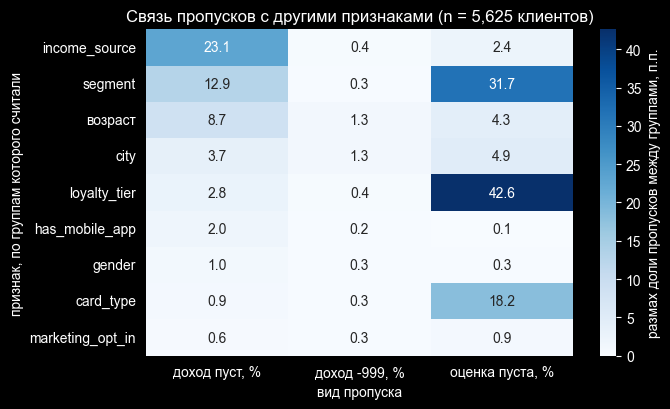

Подробно по группам:


клиентов  доход пуст, %  доход -999, %  оценка пуста, %
segment          Private                       225           17.3            0.9             33.8
                 Зарплатный                   1621            4.4            1.0             59.1
                 Массовый                     2861           13.2            0.7             65.5
                 Премиальный                   918            9.3            1.0             44.6
income_source    Зарплата в другом банке      1540            4.6            1.0             57.3
                 Зарплата в нашем банке       2519            3.5            0.9             59.5
                 Не указан                    1566           26.6            0.6             59.7
loyalty_tier     Базовый                      2786           10.7            1.0             68.2
                 Золото                        993            9.0            0.9             29.8
                 Платина                       305           11.8            0.7             25.6
                 Серебро                      1541            9.9            0.6             67.6
has_mobile_app   Да                           3450           11.0            0.8             58.9
                 Нет                          2175            9.0            1.0             59.0
marketing_opt_in Да                           4934           10.3            0.9             59.1
                 Нет                           691            9.7            0.6             58.2
gender           Ж                            2772           10.7            1.0             59.1
                 М                            2853            9.7            0.7             58.8
card_type        Дебетовая                    3971           10.4            0.9             60.7
                 Кредитная                    1190            9.5            0.8             59.6
                 Премиальная                   464           10.1            1.1             42.5
city             Екатеринбург                  748           10.3            0.7             57.4
                 Казань                        668            9.0            1.0             58.1
                 Москва                       1631            9.4            1.1             57.9
                 Нижний Новгород               934           12.7            0.2             62.3
                 Новосибирск                   653           10.0            1.5             59.0
                 Санкт-Петербург               991           10.1            0.6             59.3
возраст          до 30                         111           16.2            0.0             61.3
                 30-40                         874           12.7            0.7             57.8
                 40-50                        1585           11.1            0.8             58.2
                 50-60                        1427           10.3            1.3             61.9
                 60+                          1628            7.5            0.7             57.6

In [27]:
age_bin = pd.cut(clients.age, [0, 30, 40, 50, 60, 120], labels=["до 30", "30-40", "40-50", "50-60", "60+"])
miss = pd.DataFrame({"доход пуст, %": clients.monthly_income.isna() * 100,
                     "доход -999, %": inc_sentinel * 100,
                     "оценка пуста, %": clients.satisfaction_score.isna() * 100})
dims = {"segment": clients.segment, "income_source": clients.income_source, "loyalty_tier": clients.loyalty_tier,
        "has_mobile_app": clients.has_mobile_app, "marketing_opt_in": clients.marketing_opt_in,
        "gender": clients.gender, "card_type": clients.card_type, "city": clients.city, "возраст": age_bin}

detail, spread = [], {}
for name, key in dims.items():
    g = miss.groupby(key, observed=True).mean().round(1)
    g.insert(0, "клиентов", key.groupby(key, observed=True).size())
    g.index = pd.MultiIndex.from_product([[name], g.index.astype(str)])
    detail.append(g)
    big = g[g["клиентов"] >= 100]                           # маленькие группы дают шумные доли
    spread[name] = (big.iloc[:, 1:].max() - big.iloc[:, 1:].min()).round(1)

sp = pd.DataFrame(spread).T.sort_values("доход пуст, %", ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.heatmap(sp, annot=True, fmt=".1f", cmap="Blues", vmin=0,
            cbar_kws={"label": "размах доли пропусков между группами, п.п."}, ax=ax)
ax.set_xlabel("вид пропуска")
ax.set_ylabel("признак, по группам которого считали")
ax.set_title(f"Связь пропусков с другими признаками (n = {len(clients):,} клиентов)")
plt.tight_layout()
plt.show()
print("Подробно по группам:")
display(pd.concat(detail))

In [28]:
clients["monthly_income_raw"] = clients["monthly_income"]
n_sent = int(inc_sentinel.sum())
clients.loc[inc_sentinel, "monthly_income"] = np.nan

n_inc_empty = int(clients.monthly_income.isna().sum()) - n_sent
n_sat_empty = int(clients.satisfaction_score.isna().sum())
n_app_empty = int(clients.app_last_login.isna().sum())

sp = pd.DataFrame(spread).T
missing_summary = pd.DataFrame([
    ("monthly_income (пусто)", n_inc_empty, n_cl_now,"оставлено NaN, не заполнено"),
    ("monthly_income (код -999)", n_sent, n_cl_now,"заменено на NaN, исходное в monthly_income_raw"),
    ("satisfaction_score", n_sat_empty, n_cl_now,"оставлено NaN, не заполнено"),
    ("app_last_login", n_app_empty, n_cl_now, "оставлено NaT (значения нет по определению)"),
], columns=["поле", "пропусков", "из клиентов", "решение"])
missing_summary["доля, %"] = (missing_summary["пропусков"] / missing_summary["из клиентов"] * 100).round(2)
display(missing_summary)

log("monthly_income", "значение -999 вместо дохода (служебный код)", "client_id со значением -999", n_sent,
    "-999", "заменено на пропуск", "NaN (исходное значение в monthly_income_raw)",
    "доход не может быть отрицательным; кода нет в описании полей; доля ~1% одинакова во всех группах")
log("monthly_income", "пустое значение", "клиенты без указанного дохода", n_inc_empty, "(пусто)", "оставлено", "NaN",
    "пропуск зависит от income_source и сегмента (MAR). Доход не входит в признаки правил групп, а заполнение выдуманными значениями "
    "исказило бы распределение; в расчётах используем только клиентов с известным доходом и указываем n")
log("satisfaction_score", "пустое значение (нет ответа в опросе)", "клиенты без оценки", n_sat_empty, "(пусто)", "оставлено", "NaN",
    "более половины клиентов не отвечали, ответы зависят от loyalty_tier (MAR); заполнение невозможно обосновать, "
    "поле порядковое и используется только по заполненным (медиана и доли)")
log("app_last_login", "пустое значение", "клиенты без приложения", n_app_empty, "(пусто)", "оставлено", "NaT",
    "структурный пропуск: пусто ровно там, где has_mobile_app = Нет")

,поле,пропусков,из клиентов,решение,"доля, %"
0,monthly_income (пусто),574,5625,"оставлено NaN, не заполнено",10.20
1,monthly_income (код -999),48,5625,"заменено на NaN, исходное в monthly_income_raw",0.85
2,satisfaction_score,3316,5625,"оставлено NaN, не заполнено",58.95
3,app_last_login,2175,5625,оставлено NaT (значения нет по определению),38.67


**Вывод по пропускам.**

- `monthly_income`: 574 пустых из 5 625 клиентов (10,20%) и ещё 48 клиентов (0,85%) со значением -999. Пустые значения зависят от `income_source`: у «Не указан» пусто 26,6% дохода против 3,5-4,6% у остальных, и от сегмента (Массовый 13,2%, Private 17,3%, Зарплатный 4,4%). От приложения, пола и маркетингового согласия пропуск не зависит. Это MAR. Код -999 распределён ровно по всем группам (размах не больше 1,3 п.п.), то есть выглядит как случайный технический код.
- `satisfaction_score`: нет оценки у 3 316 клиентов (58,95%). Пропуск зависит от `loyalty_tier` (Золото 29,8% и Платина 25,6% против 67,6-68,2% у Серебра и Базового) и от сегмента, а от приложения, пола и города почти нет. Это тоже MAR; MNAR (недовольные не отвечают) по данным проверить нельзя.
- `app_last_login`: пусто ровно у 2 175 клиентов без приложения. Это структурный пропуск: значения нет по определению.

**Решение: ничего не заполняем.** Доход и оценка не входят в признаки правил групп из задания, оценка пропущена более чем у половины клиентов, а заполнение выдуманными значениями исказило бы распределение. В расчётах будем использовать только клиентов с известным значением и указывать n. Код -999 заменён на NaN, исходное значение сохранено в `monthly_income_raw`.

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

Наибольший разрыв между соседними значениями дохода: 318 -> 15,900 руб. (в 50 раз)
Значений ниже разрыва: 219 из 5,003 (4.38%)


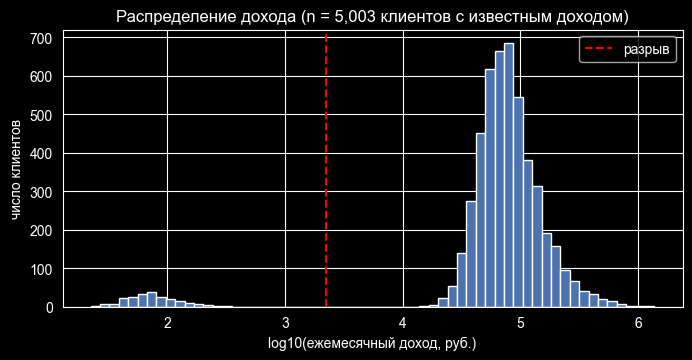

,сегмент,n низких,медиана x1000,Q1 x1000,Q3 x1000,n основных,медиана,Q1,Q3
0,Массовый,120,60050.0,46400.0,77075.0,2341,60400.0,46400.0,79400.0
1,Зарплатный,68,76250.0,62575.0,99375.0,1466,78200.0,60500.0,101375.0
2,Премиальный,28,154200.0,125750.0,194325.0,796,145400.0,113450.0,193575.0
3,Private,3,238700.0,231400.0,278350.0,181,336900.0,252700.0,446300.0


,"граница, руб.",выше границы,максимум
segment,,,
Private,1047513.0,2,1382100.0
Зарплатный,219884.0,6,295100.0
Массовый,177736.0,3,195100.0
Премиальный,431436.0,1,593900.0


Возраст на 30.06.2025: 22.5 - 88.9 лет: выбросов нет


In [29]:
inc_pos = clients.monthly_income.dropna()
v = np.sort(inc_pos.values)
ratios = v[1:] / v[:-1]
i = int(ratios.argmax())
gap_lo, gap_hi = float(v[i]), float(v[i + 1])
print(f"Наибольший разрыв между соседними значениями дохода: {gap_lo:,.0f} -> {gap_hi:,.0f} руб. (в {ratios[i]:.0f} раз)")
low_mask = clients.monthly_income <= gap_lo
print("Значений ниже разрыва:", share(int(low_mask.sum()), len(inc_pos)))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(np.log10(inc_pos), bins=60, color="#4C72B0")
ax.axvline(np.log10(gap_lo * gap_hi) / 2, color="red", ls="--", label="разрыв")
ax.set_xlabel("log10(ежемесячный доход, руб.)")
ax.set_ylabel("число клиентов")
ax.set_title(f"Распределение дохода (n = {len(inc_pos):,} клиентов с известным доходом)")
ax.legend()
plt.show()

cmp_rows = []
for seg in ["Массовый", "Зарплатный", "Премиальный", "Private"]:
    lo = clients.loc[low_mask & (clients.segment == seg), "monthly_income"] * 1000
    body = clients.loc[~low_mask & (clients.segment == seg), "monthly_income"].dropna()
    cmp_rows.append((seg, len(lo), lo.median(), lo.quantile(.25), lo.quantile(.75),
                     len(body), body.median(), body.quantile(.25), body.quantile(.75)))
display(pd.DataFrame(cmp_rows, columns=["сегмент", "n низких", "медиана x1000", "Q1 x1000", "Q3 x1000",
                                        "n основных", "медиана", "Q1", "Q3"]).round(0))

body_inc = clients.loc[~low_mask].dropna(subset=["monthly_income"])
lg = np.log10(body_inc.monthly_income)
q1, q3 = lg.groupby(body_inc.segment).quantile(.25), lg.groupby(body_inc.segment).quantile(.75)
hi_fence = 10 ** (q3 + 1.5 * (q3 - q1))
above_inc = body_inc.monthly_income > body_inc.segment.map(hi_fence)
display(pd.DataFrame({"граница, руб.": hi_fence.round(0), "выше границы": above_inc.groupby(body_inc.segment).sum(),
                      "максимум": body_inc.groupby("segment").monthly_income.max()}))
print("Возраст на 30.06.2025:", clients.age.min(), "-", clients.age.max(), "лет: выбросов нет")

,операций,выше границы,ниже границы,"максимум, руб.","медиана, руб.","выше, %","ниже, %"
category,,,,,,,
АЗС,57613,188,232,38733.0,1844.0,0.33,0.40
Аптеки,45114,131,168,24551.0,793.0,0.29,0.37
Кафе и рестораны,84320,285,354,41228.0,1552.0,0.34,0.42
Одежда и обувь,64255,207,283,96667.0,4175.0,0.32,0.44
Онлайн-сервисы,43720,154,185,10857.0,502.0,0.35,0.42
Продукты,163707,560,677,62487.0,976.0,0.34,0.41
Развлечения и досуг,47193,145,173,121692.0,2580.0,0.31,0.37
Связь и интернет,48483,153,179,19249.0,596.0,0.32,0.37
Транспорт,65450,180,245,2499.0,98.0,0.28,0.37


Всего выше границы: 2,003 из 619,855 (0.323%) | ниже границы: 2,496 из 619,855 (0.403%)


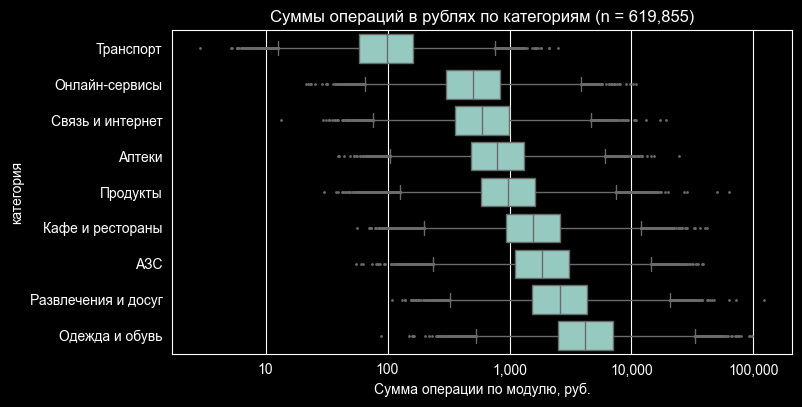

In [30]:
rub = tx[tx.currency == "RUB"].copy()
rub["abs_amt"] = rub.amount.abs()
la = np.log(rub.abs_amt)
q1c, q3c = la.groupby(rub.category).quantile(.25), la.groupby(rub.category).quantile(.75)
rub["hi"] = rub.category.map(np.exp(q3c + 1.5 * (q3c - q1c)))
rub["lo"] = rub.category.map(np.exp(q1c - 1.5 * (q3c - q1c)))
rub["above"] = rub.abs_amt > rub.hi
rub["below"] = rub.abs_amt < rub.lo

det = pd.DataFrame({
    "операций": rub.groupby("category").size(),
    "выше границы": rub.groupby("category").above.sum(),
    "ниже границы": rub.groupby("category").below.sum(),
    "максимум, руб.": rub.groupby("category").abs_amt.max().round(0),
    "медиана, руб.": rub.groupby("category").abs_amt.median().round(0),
})
det["выше, %"] = (det["выше границы"] / det["операций"] * 100).round(2)
det["ниже, %"] = (det["ниже границы"] / det["операций"] * 100).round(2)
display(det)
print("Всего выше границы:", share(int(rub.above.sum()), len(rub)), "| ниже границы:", share(int(rub.below.sum()), len(rub)))

fig, ax = plt.subplots(figsize=(8, 4.2))
order = det.sort_values("медиана, руб.").index
sns.boxplot(data=rub, y="category", x=np.log10(rub.abs_amt), order=order, orient="h", fliersize=1, ax=ax)
ticks = [1, 2, 3, 4, 5]; ax.set_xticks(ticks); ax.set_xticklabels([f"{10 ** t:,.0f}" for t in ticks])
ax.set_xlabel("Сумма операции по модулю, руб.")
ax.set_ylabel("категория")
ax.set_title(f"Суммы операций в рублях по категориям (n = {len(rub):,})")
plt.show()

In [31]:
n_low = int(low_mask.sum())
clients["income_x1000"] = low_mask
clients.loc[low_mask, "monthly_income"] = clients.loc[low_mask, "monthly_income"] * 1000

sens = pd.DataFrame({
    "как есть": clients.assign(x=clients.monthly_income_raw.where(clients.monthly_income_raw > 0)).groupby("segment").x.median(),
    "исключить низкие": clients.loc[~low_mask].groupby("segment").monthly_income.median(),
    "x1000 (принято)": clients.groupby("segment").monthly_income.median(),
}).round(0)
display(sens)

log("monthly_income", f"{n_low} значений ниже разрыва ({gap_lo:,.0f} -> {gap_hi:,.0f} руб.): вероятно, записаны в тысячах рублей", "клиенты с доходом ниже разрыва", n_low,
    "22.3 ... 318.0", "исправлено умножением на 1000, исходное в monthly_income_raw, флаг income_x1000", "22 300 ... 318 000",
    f"разрыв между кластерами в {ratios[i]:.0f} раз, при умножении на 1000 медиана и квартили кластера совпадают с основной массой "
    "того же сегмента (таблица сравнения выше). "
    "Причину в источнике установить не удалось, поэтому флаг оставлен; доход не входит в признаки групп, на выводы не влияет")
log("monthly_income", "высокие значения дохода выше IQR-границы (Private, Премиальный)", "клиенты выше границы сегмента", int(above_inc.sum()),
    f"максимум {body_inc.monthly_income.max():,.0f}", "оставлено", "без изменений",
    "значения правдоподобны для своих сегментов и не отделены разрывом от основной массы; удаление исказило бы сегменты Private и Премиальный")

tx["amt_high"] = False
tx.loc[rub.index[rub.above], "amt_high"] = True
n_above = int(rub.above.sum()); n_below = int(rub.below.sum())

ok = rub[(rub.status == "успешно")]
tot_share = ok.loc[ok.above, "abs_amt"].sum() / ok.abs_amt.sum()
print(f"Операции выше границы дают {tot_share:.1%} суммы успешных рублёвых операций, но {ok.above.mean():.2%} их числа")
print("Медиана суммы успешных операций: со всеми", f"{ok.abs_amt.median():,.0f}", "| без выбросов", f"{ok.loc[~ok.above, 'abs_amt'].median():,.0f}")

log("amount", "суммы выше и ниже IQR-границ внутри категории (лог-шкала)", "рублёвые операции вне границ", n_above + n_below,
    f"выше: {n_above:,}, ниже: {n_below:,}", "оставлено, добавлен флаг amt_high", "без изменений",
    f"суммы близки к логнормальному распределению: за границами {n_above / len(rub):.2%} выше и {n_below / len(rub):.2%} ниже, "
    "а для нормального распределения Тьюки-границы дают около 0.35% с каждой стороны; доля стабильна по месяцам, целых сумм не больше, чем среди всех. "
    "Следов ошибки нет. Числа даны на момент 3.4, до фильтров 3.5. "
    "Выбросы почти не влияют на медиану; на суммы влияют (доля в сумме выше доли по числу), поэтому метрику активности выбираем по числу операций или медиане")

,как есть,исключить низкие,x1000 (принято)
segment,,,
Private,332550.0,336900.0,332550.0
Зарплатный,76900.0,78200.0,78100.0
Массовый,59100.0,60400.0,60400.0
Премиальный,143600.0,145400.0,146300.0


Операции выше границы дают 2.3% суммы успешных рублёвых операций, но 0.30% их числа
Медиана суммы успешных операций: со всеми 1,072 | без выбросов 1,068


**Вывод по выбросам.**

*Обнаружено.*
- **Доход.** Между значениями 318 и 15 900 рублей разрыв в 50 раз: 219 из 5 003 клиентов (4,38%) лежат ниже него. Если умножить их доход на 1000, медиана и квартили совпадают с основной массой того же сегмента (Массовый 60 050 против 60 400, Зарплатный 76 250 против 78 200, Премиальный 154 200 против 145 400); у Private всего 3 значения, и сравнение малоинформативно. Это похоже на доход, записанный в тысячах рублей.
- **Верхний хвост дохода** (12 клиентов выше границы своего сегмента, максимум 1 382 100 у Private) от основной массы разрывом не отделён и для своего сегмента правдоподобен.
- **Возраст** 22,5-88,9 лет: выбросов нет.
- **Суммы операций** сильно скошены вправо, поэтому границы считаем на логарифмической шкале внутри категории. За границами 2 003 операции выше (0,323%) и 2 496 ниже (0,403%) из 619 855 рублёвых, это близко к ожидаемым 0,35% с каждой стороны для нормального распределения логарифма. Доля стабильна по месяцам, целых сумм среди выбросов столько же, сколько среди всех.

*Решено.*
- **Доход ниже разрыва** умножен на 1000 с флагом `income_x1000`, исходное в `monthly_income_raw`. Причину в источнике установить не удалось, поэтому это гипотеза с проверкой чувствительности (таблица ниже): исключение этих клиентов даёт почти те же медианы, а оставить как есть занижает их на 1-3 тысячи. Доход не входит в признаки групп, на выводы это не влияет.
- **Суммы операций оставлены**, добавлен флаг `amt_high`. Операции выше границы дают 2,3% суммы успешных рублёвых операций, но 0,30% их числа, на медиану почти не влияют (1 072 против 1 068). Поэтому в метрике активности лучше опираться на число операций или медиану, а не на сумму.

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [32]:
funnel = [("Исходно: transactions.csv", len(tx_raw), tx_raw.client_id.nunique())]
funnel.append(("Удалены дубли txn_id (3.2б)", len(tx), tx.client_id.nunique()))

#  период данных
in_period = tx.txn_datetime.between(DATA_START, DATA_END + pd.Timedelta(days=1) - pd.Timedelta(seconds=1))
n_out_before = int((tx.txn_datetime < DATA_START).sum())
n_out_after = int((tx.txn_datetime > DATA_END + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)).sum())
tx = tx[in_period]
funnel.append(("Только период 2024-01-01 .. 2025-06-30", len(tx), tx.client_id.nunique()))

#  клиенты, которых нет в справочнике действующих
ids_known = set(clients.client_id)
ids_conf = set(clients_conflict.client_id)
orphan = ~tx.client_id.isin(ids_known | ids_conf)
n_orphan_ops, n_orphan_ids = int(orphan.sum()), int(tx.loc[orphan, "client_id"].nunique())
tx = tx[~orphan]
funnel.append(("Только клиенты из справочника", len(tx), tx.client_id.nunique()))

#  клиенты с неоднозначными атрибутами (3.2б)
conf_ops = tx.client_id.isin(ids_conf)
n_conf_ops = int(conf_ops.sum())
tx = tx[~conf_ops]
funnel.append(("Без клиентов с конфликтом атрибутов", len(tx), tx.client_id.nunique()))

fun = pd.DataFrame(funnel, columns=["шаг", "операций", "клиентов"])
fun["убрано операций"] = (-fun["операций"].diff()).fillna(0).astype(int)
fun["осталось, % от исходных"] = (fun["операций"] / len(tx_raw) * 100).round(2)
display(fun)

log("txn_datetime", "операции вне периода данных 2024-01-01..2025-06-30", "операции вне периода", n_out_before + n_out_after,
    f"до периода: {n_out_before}, после: {n_out_after} (до 2026-07)", "удалено из рабочей таблицы", "только 2024-01-01 .. 2025-06-30",
    "вне заявленного периода; даты после даты выгрузки (30.06.2025) невозможны. Исходник сохранён в tx_raw")
log("client_id", "клиенты есть в операциях, но нет в справочнике действующих", f"{n_orphan_ids} client_id", n_orphan_ops,
    "справочник на 30.06.2025", "операции исключены из рабочей таблицы", "только клиенты из справочника",
    "для них нет сегмента, возраста и согласия на коммуникацию, а согласие обязательно; их операции исчезают к началу 2025 ")
log("client_id", "клиенты с неоднозначными атрибутами", f"{len(ids_conf)} client_id", n_conf_ops,
    "client_id из clients_conflict", "операции исключены из рабочей таблицы", "без этих клиентов",
    "сегмент и город неизвестны, правило группы к ним неприменимо")

tx_clean = tx.copy()
tx_clean["is_rub"] = tx_clean.currency == "RUB"
tx_clean["month"] = tx_clean.txn_datetime.dt.to_period("M")
tx_clean["period"] = np.where(tx_clean.txn_datetime < EVAL_START, "base", "eval")
clients_clean = clients.copy()

n_t = len(tx_clean)
print("Статусы:", {k: f"{v:,} ({v / n_t:.1%})" for k, v in tx_clean.status.value_counts().items()}, "| из", f"{n_t:,}")
print("Не RUB:", share(int((~tx_clean.is_rub).sum()), n_t), "| без времени:", share(int((~tx_clean.has_time).sum()), n_t))
print("Клиентов в справочнике без операций в периоде:",
      share(int((~clients_clean.client_id.isin(tx_clean.client_id)).sum()), len(clients_clean)))

log("currency", "операции в EUR/USD: суммы в валюте, курса в данных нет", "операции не в RUB", int((~tx_clean.is_rub).sum()),
    "медиана ~11 (EUR/USD) против ~1063 (RUB)", "оставлено, добавлен флаг is_rub", "is_rub=False",
    "строки не удалялись: для метрики по числу операций валюта не важна; суммы в рублях считаем только по is_rub")
log("status", "статусы «отклонено» и «возврат» не являются тратой", "операции со статусами отклонено и возврат",
    int((tx_clean.status != "успешно").sum()), "отклонено, возврат", "оставлено", "без изменений",
    "решение, считать ли их активностью; в таблице есть поле status")

for name, d, key in [("tx_clean", tx_clean, "txn_id"), ("clients_clean", clients_clean, "client_id")]:
    assert d[key].is_unique, name
assert tx_clean.client_id.isin(clients_clean.client_id).all()
assert tx_clean.txn_datetime.between(DATA_START, DATA_END + pd.Timedelta(days=1)).all()
print("tx_clean:", tx_clean.shape, "| clients_clean:", clients_clean.shape)

,шаг,операций,клиентов,убрано операций,"осталось, % от исходных"
0,Исходно: transactions.csv,623808,5994,0,100.00
1,Удалены дубли txn_id (3.2б),622308,5994,1500,99.76
2,Только период 2024-01-01 .. 2025-06-30,622216,5994,92,99.74
3,Только клиенты из справочника,593295,5633,28921,95.11
4,Без клиентов с конфликтом атрибутов,592149,5619,1146,94.92


Статусы: {'успешно': '573,126 (96.8%)', 'отклонено': '11,918 (2.0%)', 'возврат': '7,105 (1.2%)'} | из 592,149
Не RUB: 2,342 из 592,149 (0.396%) | без времени: 47,410 из 592,149 (8.01%)
Клиентов в справочнике без операций в периоде: 6 из 5,625 (0.107%)
tx_clean: (592149, 15) | clients_clean: (5625, 19)


In [33]:
cfun = pd.DataFrame([
    ("Исходно: clients.csv, строк", len(clients_raw)),
    ("После удаления точных копий", len(clients_raw) - n_exact_cl),
    ("Без клиентов с конфликтом атрибутов", len(clients)),
    ("Из них с операциями в периоде", int(clients.client_id.isin(tx.client_id).sum())),
], columns=["шаг", "клиентов (строк)"])
display(cfun)

,шаг,клиентов (строк)
0,"Исходно: clients.csv, строк",5694
1,После удаления точных копий,5653
2,Без клиентов с конфликтом атрибутов,5625
3,Из них с операциями в периоде,5619


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [34]:
COLS = ["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"]
cleaning_log = pd.DataFrame(log_rows, columns=COLS)
print("Решений в журнале:", len(cleaning_log))
display(cleaning_log[["field", "issue", "n_rows", "action"]])

Решений в журнале: 26


,field,issue,n_rows,action
0,"registration_date, card_open_date",дата хранится текстом «ДД.ММ.ГГГГ»,5694,преобразовано
1,birth_date,дата хранится текстом «ГГГГ-ММ-ДД»,5694,преобразовано
2,app_last_login,месяц хранится текстом «ГГГГ-ММ»,3496,преобразовано
3,txn_datetime,два формата записи: с временем и только дата,623808,"преобразовано, добавлен флаг has_time"
4,amount,сумма хранится текстом с десятичной запятой,623808,преобразовано
5,"monthly_income, satisfaction_score",числа хранятся текстом,5113,преобразовано
6,age,"возраст в данных отсутствует, есть только дата...",5694,добавлен
7,city,17 написаний вместо 6 городов,1671,нормализовано
8,category,12 написаний вместо 9 категорий,53855,нормализовано
9,mcc_code / category,MCC не соответствует категории,1624,"оставлено, добавлен флаг mcc_mismatch"


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

In [35]:
sns.set_theme(style="whitegrid", context="notebook")
SEG = ["Массовый", "Зарплатный", "Премиальный", "Private"]

ok = tx_clean[tx_clean.status == "успешно"]
ops_2024 = (ok[ok.period == "base"].groupby("client_id").size()
              .reindex(clients_clean.client_id).fillna(0) / 12)
amt_rub = ok.loc[ok.is_rub, "amount"]

def describe(s, name, unit, ordinal=False):
    s = s.dropna()
    q1, me, q3 = s.quantile([.25, .5, .75])
    iqr = q3 - q1
    bowley = (q3 + q1 - 2 * me) / iqr if iqr > 0 else np.nan
    skew = s.skew()
    if ordinal:
        choice = "медиана, МКР, мода (шкала порядковая, среднее не считаем)"
    elif abs(skew) < 0.6 and abs(bowley) < 0.1:
        choice = "среднее и s (форма близка к симметричной)"
    else:
        choice = "медиана и МКР (сильная асимметрия вправо)"
    return {"признак": name, "единицы": unit, "n": len(s), "медиана": me, "Q1": q1, "Q3": q3, "МКР": iqr,
            "МАО": (s - me).abs().median(),
            "среднее": np.nan if ordinal else s.mean(), "s": np.nan if ordinal else s.std(),
            "асимметрия": np.nan if ordinal else skew, "коэф. Боули": bowley,
            "мин": s.min(), "макс": s.max(), "выбор меры": choice}

desc = pd.DataFrame([
    describe(clients_clean.age, "возраст", "лет"),
    describe(clients_clean.monthly_income, "доход", "руб./мес."),
    describe(ops_2024, "операций на клиента в 2024", "операций/мес."),
    describe(amt_rub, "сумма операции (RUB, успешные)", "руб."),
    describe(clients_clean.satisfaction_score, "оценка обслуживания", "баллы 1-5", ordinal=True),
]).set_index("признак")
display(desc.round(2))
ab = pd.cut(clients_clean.age, [80, 82, 84, 86, 88, 90], right=False).value_counts().sort_index()
n_top = int((clients_clean.age >= 88).sum()); n_near = int(((clients_clean.age >= 84) & (clients_clean.age < 88)).sum() / 2)
print("Клиентов по возрасту у верхнего края:", {str(k): int(v) for k, v in ab.items()})
log("birth_date", "избыток клиентов у верхнего края возраста (88-89 лет): обрезанный край распределения", "клиенты 88 лет и старше",
    n_top, f"{n_top} клиентов против около {n_near} в двухлетнем интервале рядом", "оставлено", "без изменений",
    "вероятно, потолок возраста при формировании данных (цензурирование); возраст используется только как порог 55+, на выводы не влияет")
print("Мода оценки обслуживания:", int(clients_clean.satisfaction_score.mode().iat[0]),
      "| доля клиентов с оценкой:", share(int(clients_clean.satisfaction_score.notna().sum()), len(clients_clean)))

,единицы,n,медиана,Q1,Q3,МКР,МАО,среднее,s,асимметрия,коэф. Боули,мин,макс,выбор меры
признак,,,,,,,,,,,,,,
возраст,лет,5625,51.70,43.00,62.00,19.00,9.50,53.35,13.92,0.51,0.08,22.50,88.90,среднее и s (форма близка к симметричной)
доход,руб./мес.,5003,75800.00,54500.00,110300.00,55800.00,25200.00,97870.58,80186.48,4.26,0.24,15900.00,1382100.00,медиана и МКР (сильная асимметрия вправо)
операций на клиента в 2024,операций/мес.,5625,5.42,3.17,8.17,5.00,2.50,6.01,4.42,1.40,0.10,0.00,41.50,медиана и МКР (сильная асимметрия вправо)
"сумма операции (RUB, успешные)",руб.,570861,1073.98,485.60,2236.93,1751.33,724.77,1867.05,2570.51,5.19,0.33,2.91,121692.01,медиана и МКР (сильная асимметрия вправо)
оценка обслуживания,баллы 1-5,2309,3.00,2.00,5.00,3.00,1.00,NaN,NaN,NaN,0.33,1.00,5.00,"медиана, МКР, мода (шкала порядковая, среднее ..."


Клиентов по возрасту у верхнего края: {'[80, 82)': 58, '[82, 84)': 35, '[84, 86)': 30, '[86, 88)': 26, '[88, 90)': 128}
Мода оценки обслуживания: 5 | доля клиентов с оценкой: 2,309 из 5,625 (41.05%)


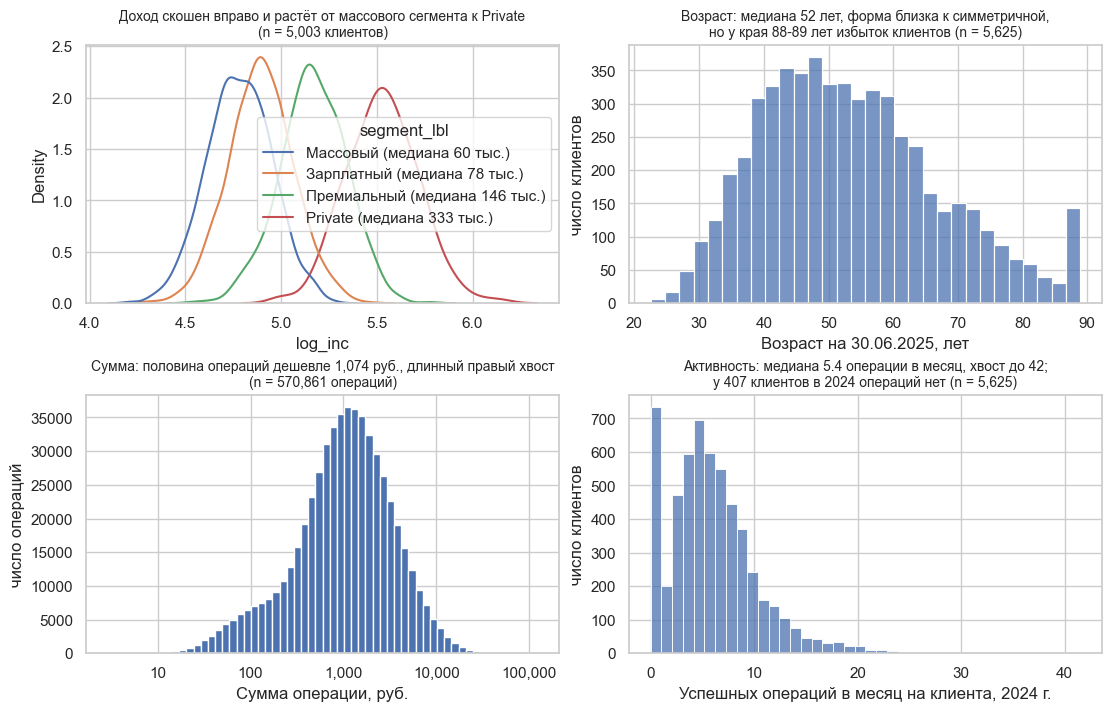

In [36]:
inc = clients_clean.dropna(subset=["monthly_income"]).assign(log_inc=lambda d: np.log10(d.monthly_income))
med_inc = inc.groupby("segment").monthly_income.median()
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")

labels = {s: f"{s} (медиана {med_inc[s] / 1000:,.0f} тыс.)" for s in SEG}
inc["segment_lbl"] = inc.segment.map(labels)
sns.kdeplot(data=inc, x="log_inc", hue="segment_lbl", hue_order=[labels[s] for s in SEG], common_norm=False, ax=axes[0, 0])
axes[0, 0].set_title(f"Доход скошен вправо и растёт от массового сегмента к Private\n(n = {len(inc):,} клиентов)", fontsize=10)

sns.histplot(clients_clean.age, bins=30, ax=axes[0, 1], color="#4C72B0")
axes[0, 1].set_xlabel("Возраст на 30.06.2025, лет"); axes[0, 1].set_ylabel("число клиентов")
axes[0, 1].set_title(f"Возраст: медиана {clients_clean.age.median():.0f} лет, форма близка к симметричной,\nно у края 88-89 лет избыток клиентов (n = {len(clients_clean):,})", fontsize=10)

axes[1, 0].hist(np.log10(amt_rub), bins=60, color="#4C72B0")
ticks = [1, 2, 3, 4, 5]; axes[1, 0].set_xticks(ticks); axes[1, 0].set_xticklabels([f"{10 ** t:,.0f}" for t in ticks])
axes[1, 0].set_xlabel("Сумма операции, руб."); axes[1, 0].set_ylabel("число операций")
axes[1, 0].set_title(f"Сумма: половина операций дешевле {amt_rub.median():,.0f} руб., длинный правый хвост\n(n = {len(amt_rub):,} операций)", fontsize=10)

sns.histplot(ops_2024, bins=40, ax=axes[1, 1], color="#4C72B0")
axes[1, 1].set_xlabel("Успешных операций в месяц на клиента, 2024 г."); axes[1, 1].set_ylabel("число клиентов")
axes[1, 1].set_title(f"Активность: медиана {ops_2024.median():.1f} операции в месяц, хвост до {ops_2024.max():.0f};\nу {int((ops_2024 == 0).sum())} клиентов в 2024 операций нет (n = {len(ops_2024):,})", fontsize=10)
plt.show()

- **Возраст** (n = 5 625): форма близка к симметричной (асимметрия 0,51, коэффициент Боули 0,08), поэтому допустимы среднее 53,4 и стандартное отклонение 13,9 года; рядом приводим медиану 51,7 и МКР 19. Но у верхнего края распределение «обрезано»: в интервале 88-89 лет 128 клиентов против примерно 28 в соседних двухлетних интервалах.
- **Доход** (n = 5 003 клиента с известным доходом): сильно скошен вправо (асимметрия 4,26; среднее 97 871 руб. при медиане 75 800), поэтому берём медиану и МКР: 75 800 руб., Q1-Q3 от 54 500 до 110 300 руб. Сегменты различаются кратно: медиана Private в 5,5 раза выше массового.
- **Активность в 2024** (n = 5 625): медиана 5,4 успешной операции в месяц на клиента (Q1-Q3 от 3,2 до 8,2), распределение скошено вправо (1,40), у 407 клиентов операций в 2024 нет.
- **Сумма операции** (n = 570 861 рублёвая успешная операция): медиана 1 074 руб. (Q1-Q3 от 486 до 2 237), хвост до 121 692 руб.; на логарифмической шкале форма близка к симметричной. Среднее (1 867 руб.) типичную операцию не описывает.
- **Оценка обслуживания**: порядковая шкала, есть у 41,05% клиентов; считаем медиану (3) и моду (5), среднее по порядковой шкале не считаем.

### 5.2. Частотные характеристики категориальных признаков

In [37]:
def freq(df, col, label):
    vc = df[col].value_counts()
    return pd.DataFrame({"признак": label, "значение": vc.index.astype(str), "n": vc.values,
                         "доля, %": (vc.values / len(df) * 100).round(1)})

cl_cols = ["segment", "loyalty_tier", "card_type", "city", "has_mobile_app", "marketing_opt_in", "income_source", "gender"]
tab_cl = pd.concat([freq(clients_clean, c, c) for c in cl_cols])
print(f"Клиенты (знаменатель: {len(clients_clean):,} клиентов)")
display(tab_cl.set_index(["признак", "значение"]))

tab_tx = pd.concat([freq(ok, "category", "category (успешные)"), freq(tx_clean, "channel", "channel (все операции)"),
                    freq(tx_clean, "status", "status (все операции)"), freq(tx_clean, "currency", "currency (все операции)")])
print(f"Операции (знаменатель: {len(ok):,} успешных или {len(tx_clean):,} всех операций, см. признак)")
display(tab_tx.set_index(["признак", "значение"]))
print("Мода: сегмент -", clients_clean.segment.mode().iat[0], "| город -", clients_clean.city.mode().iat[0],
      "| категория -", ok.category.mode().iat[0])

Клиенты (знаменатель: 5,625 клиентов)


n  доля, %
признак          значение                              
segment          Массовый                 2861     50.9
                 Зарплатный               1621     28.8
                 Премиальный               918     16.3
                 Private                   225      4.0
loyalty_tier     Базовый                  2786     49.5
                 Серебро                  1541     27.4
                 Золото                    993     17.7
                 Платина                   305      5.4
card_type        Дебетовая                3971     70.6
                 Кредитная                1190     21.2
                 Премиальная               464      8.2
city             Москва                   1631     29.0
                 Санкт-Петербург           991     17.6
                 Нижний Новгород           934     16.6
                 Екатеринбург              748     13.3
                 Казань                    668     11.9
                 Новосибирск               653     11.6
has_mobile_app   Да                       3450     61.3
                 Нет                      2175     38.7
marketing_opt_in Да                       4934     87.7
                 Нет                       691     12.3
income_source    Зарплата в нашем банке   2519     44.8
                 Не указан                1566     27.8
                 Зарплата в другом банке  1540     27.4
gender           М                        2853     50.7
                 Ж                        2772     49.3

Операции (знаменатель: 573,126 успешных или 592,149 всех операций, см. признак)


n  доля, %
признак                 значение                            
category (успешные)     Продукты             151360     26.4
                        Кафе и рестораны      78235     13.7
                        Транспорт             61001     10.6
                        Одежда и обувь        58538     10.2
                        АЗС                   53232      9.3
                        Связь и интернет      44894      7.8
                        Развлечения и досуг   43474      7.6
                        Аптеки                41808      7.3
                        Онлайн-сервисы        40584      7.1
channel (все операции)  Карта                301351     50.9
                        СБП                  107331     18.1
                        Токен                 99902     16.9
                        Онлайн-банк           83565     14.1
status (все операции)   успешно              573126     96.8
                        отклонено             11918      2.0
                        возврат                7105      1.2
currency (все операции) RUB                  589807     99.6
                        EUR                    1187      0.2
                        USD                    1155      0.2

Мода: сегмент - Массовый | город - Москва | категория - Продукты


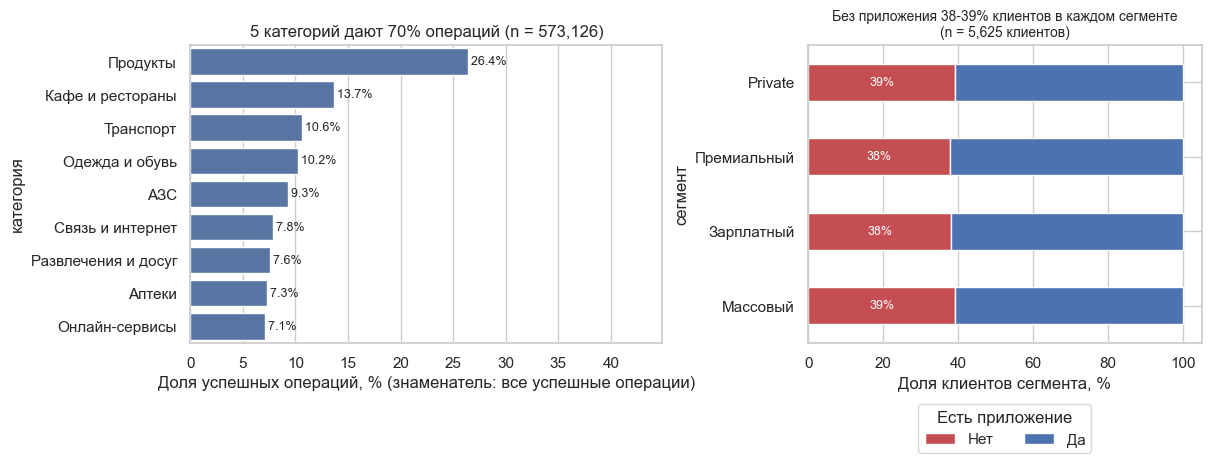

In [38]:
cat_share = ok.category.value_counts(normalize=True) * 100
cum = cat_share.cumsum()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained", gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
sns.barplot(x=cat_share.values, y=cat_share.index, color="#4C72B0", ax=ax)
for i, (v, c_) in enumerate(zip(cat_share.values, cum.values)):
    ax.text(v + 0.3, i, f"{v:.1f}% ", va="center", fontsize=9)
ax.set_xlim(0, cat_share.max() * 1.7)
ax.set_xlabel("Доля успешных операций, % (знаменатель: все успешные операции)"); ax.set_ylabel("категория")
n_top = int((cum <= 70).sum()) + 1
ax.set_title(f"{n_top} категорий дают 70% операций (n = {len(ok):,})")

app = (pd.crosstab(clients_clean.segment, clients_clean.has_mobile_app, normalize="index").reindex(SEG) * 100)[["Нет", "Да"]]
app.plot(kind="barh", stacked=True, ax=axes[1], color=["#C44E52", "#4C72B0"])
for i, seg in enumerate(app.index):
    axes[1].text(app.loc[seg, "Нет"] / 2, i, f"{app.loc[seg, 'Нет']:.0f}%", ha="center", va="center", color="white", fontsize=9)
axes[1].set_xlabel("Доля клиентов сегмента, %"); axes[1].set_ylabel("сегмент")
axes[1].legend(title="Есть приложение", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
axes[1].set_title(f"Без приложения {app['Нет'].min():.0f}-{app['Нет'].max():.0f}% клиентов в каждом сегменте\n(n = {len(clients_clean):,} клиентов)", fontsize=10)
plt.show()

**Вывод по частотам.** Клиенты (знаменатель 5 625): массовый сегмент 50,9%, базовый уровень лояльности 49,5%, дебетовая карта 70,6%, Москва 29,0%, приложение есть у 61,3% (без приложения 38,7%), согласие на коммуникацию у 87,7%, зарплата в нашем банке у 44,8%. Операции: категория «Продукты» лидирует (26,4% успешных), пять категорий дают 70% операций; каналы: карта 50,9%, СБП 18,1%, токен 16,9%, онлайн-банк 14,1%; успешных операций 96,8%, отклонённых 2,0%, возвратов 1,2%, рублей 99,6%. Доля клиентов без приложения почти одинакова во всех сегментах (38-39%), поэтому эффект «нет приложения» не сводится к сегменту.


### 5.3. Динамика по месяцам

Успешных операций в месяц: 2025 к среднему 2024 -> -17.2%; январь-июнь 2025 к январю-июню 2024 -> -10.2%
Только клиенты с операциями в 2024 (их 5,218 из 5,625): -11.8%; остальные клиенты дали 2,856 операций в 2025 (1.7% всех) и частично компенсируют падение


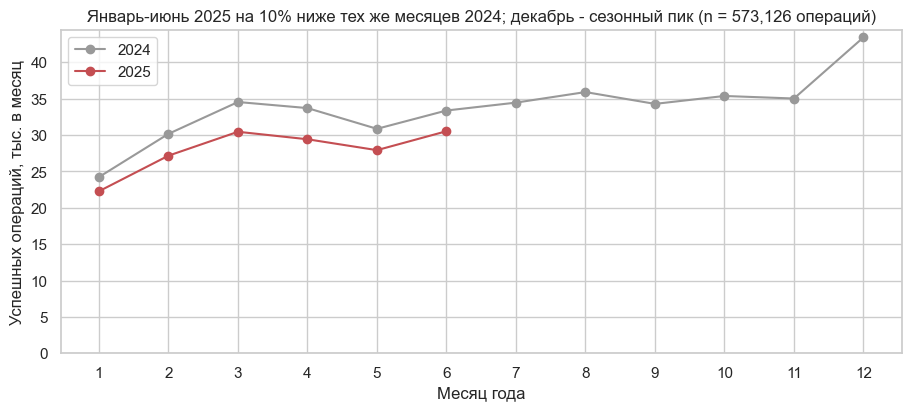

In [39]:
by_month = ok.groupby("month").size()
cal = pd.DataFrame({"2024": by_month[by_month.index.year == 2024].values,
                    "2025": list(by_month[by_month.index.year == 2025].values) + [np.nan] * 6}, index=range(1, 13))
h1_24, h1_25 = cal.loc[1:6, "2024"].sum(), cal.loc[1:6, "2025"].sum()
naive = (h1_25 / 6) / (cal["2024"].sum() / 12) - 1
like = h1_25 / h1_24 - 1
hist_ids = ok.loc[ok.period == "base", "client_id"].unique()
like_hist = ok[(ok.period == "eval") & ok.client_id.isin(hist_ids)].shape[0] / h1_24 - 1
new_ops = ok[(ok.period == "eval") & ~ok.client_id.isin(hist_ids)].shape[0]
print(f"Успешных операций в месяц: 2025 к среднему 2024 -> {naive:+.1%}; январь-июнь 2025 к январю-июню 2024 -> {like:+.1%}")
print(f"Только клиенты с операциями в 2024 (их {len(hist_ids):,} из {len(clients_clean):,}): {like_hist:+.1%}; "
      f"остальные клиенты дали {new_ops:,} операций в 2025 ({new_ops / h1_25:.1%} всех) и частично компенсируют падение")

fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.plot(cal.index, cal["2024"] / 1000, marker="o", label="2024", color="#999999")
ax.plot(cal.index, cal["2025"] / 1000, marker="o", label="2025", color="#C44E52")
ax.set_xticks(range(1, 13)); ax.set_ylim(0, None)
ax.set_xlabel("Месяц года"); ax.set_ylabel("Успешных операций, тыс. в месяц")
ax.set_title(f"Январь-июнь 2025 на {abs(like):.0%} ниже тех же месяцев 2024; декабрь - сезонный пик (n = {len(ok):,} операций)")
ax.legend(); plt.show()

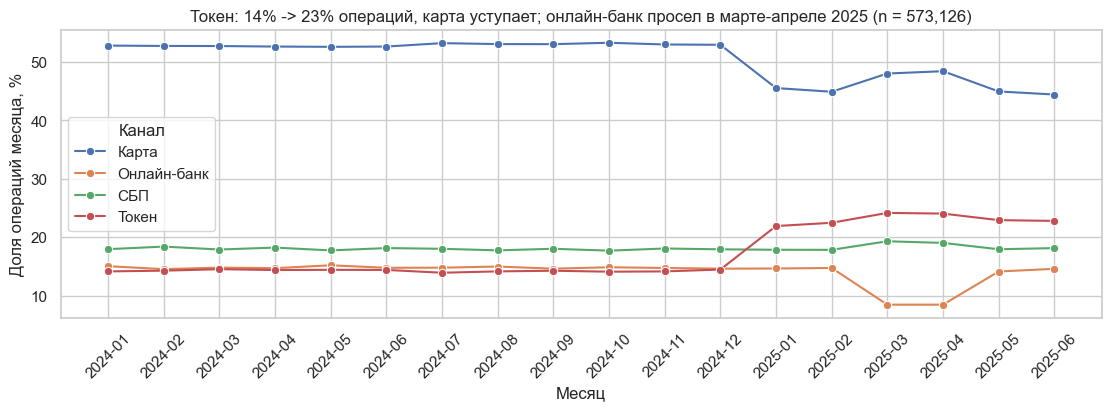

,"2024, среднее за месяц","янв.-июнь 2025, среднее за месяц","изменение, п.п."
channel,,,
Карта,52.9,46.0,-6.9
Онлайн-банк,14.8,12.5,-2.3
СБП,18.0,18.4,0.4
Токен,14.3,23.1,8.8


In [40]:
ch = (ok.groupby(["month", "channel"]).size().unstack() )
ch_share = ch.div(ch.sum(axis=1), axis=0) * 100                          # знаменатель: все успешные операции месяца
tidy = ch_share.reset_index().melt(id_vars="month", var_name="channel", value_name="share")
tidy["month"] = tidy.month.astype(str)
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
sns.lineplot(data=tidy, x="month", y="share", hue="channel", marker="o", ax=ax)
ax.set_xlabel("Месяц"); ax.set_ylabel("Доля операций месяца, %")
ax.tick_params(axis="x", rotation=45)
tok_24 = ch_share.loc[ch_share.index.year == 2024, "Токен"].mean(); tok_25 = ch_share.loc[ch_share.index.year == 2025, "Токен"].mean()
ax.set_title(f"Токен: {tok_24:.0f}% -> {tok_25:.0f}% операций, карта уступает; онлайн-банк просел в марте-апреле 2025 (n = {len(ok):,})")
ax.legend(title="Канал"); plt.show()
car_24 = ch_share.loc[ch_share.index.year == 2024, "Карта"].mean(); car_25 = ch_share.loc[ch_share.index.year == 2025, "Карта"].mean()


tbl = pd.DataFrame({"2024, среднее за месяц": ch_share.loc[ch_share.index.year == 2024].mean(),
                    "янв.-июнь 2025, среднее за месяц": ch_share.loc["2025-01":"2025-06"].mean()}).round(1)
tbl["изменение, п.п."] = (tbl.iloc[:, 1] - tbl.iloc[:, 0]).round(1)
display(tbl)

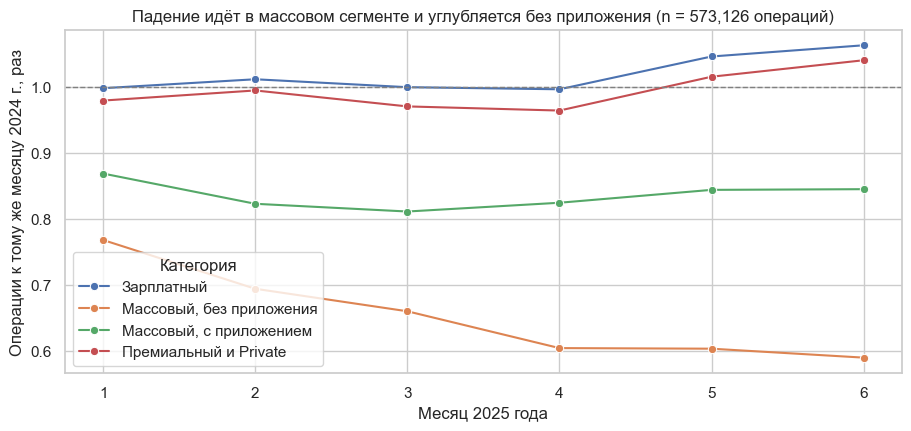

mon,1,2,3,4,5,6
cohort,,,,,,
Зарплатный,1.00,1.01,1.00,1.00,1.05,1.06
"Массовый, без приложения",0.77,0.69,0.66,0.60,0.60,0.59
"Массовый, с приложением",0.87,0.82,0.81,0.82,0.84,0.84
Премиальный и Private,0.98,0.99,0.97,0.96,1.01,1.04


In [41]:
ok_c = ok.merge(clients_clean[["client_id", "segment", "has_mobile_app"]], on="client_id")
ok_c["cohort"] = np.select(
    [(ok_c.segment == "Массовый") & (ok_c.has_mobile_app == "Нет"), (ok_c.segment == "Массовый") & (ok_c.has_mobile_app == "Да"),
     ok_c.segment == "Зарплатный"],
    ["Массовый, без приложения", "Массовый, с приложением", "Зарплатный"], default="Премиальный и Private")
ok_c["mon"] = ok_c.month.dt.month; ok_c["yr"] = ok_c.month.dt.year
c24 = ok_c[ok_c.yr == 2024].groupby(["cohort", "mon"]).size()
c25 = ok_c[ok_c.yr == 2025].groupby(["cohort", "mon"]).size()
ratio = (c25 / c24.reindex(c25.index)).rename("ratio").reset_index()
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
sns.lineplot(data=ratio, x="mon", y="ratio", hue="cohort", marker="o", ax=ax)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("Месяц 2025 года"); ax.set_ylabel("Операции к тому же месяцу 2024 г., раз")
ax.set_title("Падение идёт в массовом сегменте и углубляется без приложения (n = %s операций)" % f"{len(ok_c):,}")
ax.legend(title="Категория"); plt.show()
display(ratio.pivot(index="cohort", columns="mon", values="ratio").round(2))

**Вывод по динамике.**
- В январе-июне 2025 успешных операций на 10,2% меньше, чем в те же месяцы 2024 (на 11,8% среди клиентов, у которых в 2024 были операции; 407 клиентов без операций в 2024 дали 2 856 операций, 1,7% всех, и частично компенсируют падение). Сравнение «в лоб» со средним месяцем 2024 даёт −17,2%: разница 7,0 п.п. - сезонность (декабрь 2024 = 1,29 среднего месяца, январь низкий).
- Канал сместился: токен вырос с 14,3% до 23,1% операций месяца, карта снизилась с 52,9% до 46,0%. Онлайн-банк в марте и апреле 2025 просел до 8,5% операций (в остальные месяцы 14,1-14,8%) и в мае вернулся: похоже на временный сбой или недоступность канала, а не на отток.
- По когортам (операции к тому же месяцу 2024): массовые без приложения 0,77 → 0,59 (падение углубляется), массовые с приложением 0,81-0,87 (ступенька в январе и дальше ровно), зарплатные 1,00-1,06 и премиальные с Private 0,96-1,04 (на уровне прошлого года).

### 5.4. Разрезы и связи между признаками

In [42]:
cl_ = clients_clean.assign(age_bin=pd.cut(clients_clean.age, [0, 40, 50, 60, 70, 120],
                           labels=["до 40", "40-50", "50-60", "60-70", "70+"]))
ok_a = ok.merge(cl_[["client_id", "segment", "has_mobile_app", "loyalty_tier", "card_type", "city", "age_bin", "income_source", "gender"]],
                on="client_id")
ok_a["mon"] = ok_a.month.dt.month; ok_a["yr"] = ok_a.month.dt.year
h1b = ok_a[(ok_a.yr == 2024) & (ok_a.mon <= 6)]; h1e = ok_a[ok_a.yr == 2025]

def h1_ratio_by(col):
    a = h1b.groupby(col, observed=True).size(); b = h1e.groupby(col, observed=True).size()
    n = cl_.groupby(col, observed=True).size()
    return pd.DataFrame({"признак": col, "значение": a.index.astype(str), "клиентов": n.reindex(a.index).values,
                         "операции 2025 к 2024, раз": (b / a).round(2).values})

slices = pd.concat([h1_ratio_by(c) for c in ["segment", "has_mobile_app", "loyalty_tier", "card_type", "age_bin", "city", "income_source", "gender"]])
print(f"Операции янв.-июнь 2025 / янв.-июнь 2024: всего {len(h1e) / len(h1b):.2f} (знаменатель: {len(h1b):,} успешных операций)")
display(slices.set_index(["признак", "значение"]))

city_seg = (h1e.groupby(["city", "segment"]).size() / h1b.groupby(["city", "segment"]).size()).unstack().reindex(columns=SEG).round(2)
mass_share = (cl_.groupby("city").segment.apply(lambda s: (s == "Массовый").mean()) * 100).round(0).rename("доля массовых, %")
display(city_seg.join(mass_share).join(h1_ratio_by("city").set_index("значение")["операции 2025 к 2024, раз"].rename("город целиком")))

Операции янв.-июнь 2025 / янв.-июнь 2024: всего 0.90 (знаменатель: 186,877 успешных операций)


клиентов  операции 2025 к 2024, раз
признак        значение                                                    
segment        Private                       225                       0.96
               Зарплатный                   1621                       1.02
               Массовый                     2861                       0.76
               Премиальный                   918                       1.00
has_mobile_app Да                           3450                       0.95
               Нет                          2175                       0.82
loyalty_tier   Базовый                      2786                       0.85
               Золото                        993                       0.99
               Платина                       305                       1.01
               Серебро                      1541                       0.90
card_type      Дебетовая                    3971                       0.88
               Кредитная                    1190                       0.93
               Премиальная                   464                       0.95
age_bin        до 40                         985                       0.95
               40-50                        1585                       0.92
               50-60                        1427                       0.90
               60-70                         888                       0.84
               70+                           740                       0.82
city           Екатеринбург                  748                       0.92
               Казань                        668                       0.93
               Москва                       1631                       0.91
               Нижний Новгород               934                       0.78
               Новосибирск                   653                       0.94
               Санкт-Петербург               991                       0.92
income_source  Зарплата в другом банке      1540                       0.85
               Зарплата в нашем банке       2519                       0.95
               Не указан                    1566                       0.85
gender         Ж                            2772                       0.91
               М                            2853                       0.89

,Массовый,Зарплатный,Премиальный,Private,"доля массовых, %",город целиком
city,,,,,,
Екатеринбург,0.77,1.03,0.97,0.99,43.0,0.92
Казань,0.77,1.05,1.00,0.91,43.0,0.93
Москва,0.76,1.02,0.98,1.00,45.0,0.91
Нижний Новгород,0.74,0.96,0.98,1.01,87.0,0.78
Новосибирск,0.77,1.00,1.07,0.98,40.0,0.94
Санкт-Петербург,0.79,1.01,1.02,0.89,45.0,0.92


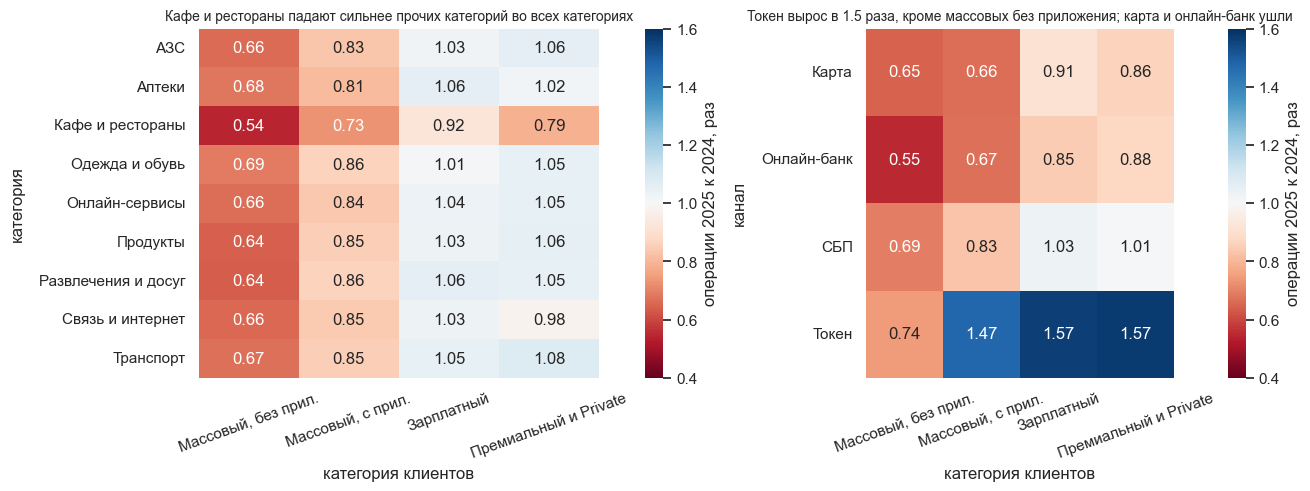

In [43]:
def cohort_of(d):
    return np.select([(d.segment == "Массовый") & (d.has_mobile_app == "Нет"), (d.segment == "Массовый") & (d.has_mobile_app == "Да"),
                      d.segment == "Зарплатный"], ["Массовый, без прил.", "Массовый, с прил.", "Зарплатный"], default="Премиальный и Private")
h1b = h1b.assign(cohort=cohort_of(h1b)); h1e = h1e.assign(cohort=cohort_of(h1e))
def idx(dim):
    a = h1b.groupby([dim, "cohort"]).size().unstack(); b = h1e.groupby([dim, "cohort"]).size().unstack()
    return (b / a)[["Массовый, без прил.", "Массовый, с прил.", "Зарплатный", "Премиальный и Private"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1]})
for ax, dim, title in [(axes[0], "category", "Кафе и рестораны падают сильнее прочих категорий во всех категориях"),
                       (axes[1], "channel", "Токен вырос в 1.5 раза, кроме массовых без приложения; карта и онлайн-банк ушли")]:
    t = idx(dim)
    sns.heatmap(t, annot=True, fmt=".2f", cmap="RdBu", center=1, vmin=0.4, vmax=1.6, ax=ax,
                cbar_kws={"label": "операции 2025 к 2024, раз"})
    ax.set_xlabel("категория клиентов"); ax.set_ylabel(dim.replace("category", "категория").replace("channel", "канал"), labelpad=10)
    ax.set_title(title, fontsize=10); ax.tick_params(axis="x", rotation=20); ax.tick_params(axis="y", rotation=0)
plt.show()

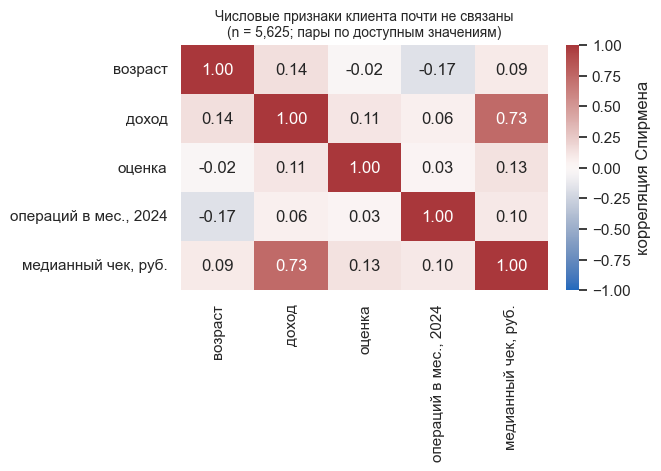

Наибольшая по модулю связь: ('доход', 'медианный чек, руб.') 0.73


In [44]:
avg_check = (ok[(ok.period == "base") & ok.is_rub].groupby("client_id").amount.median().reindex(clients_clean.client_id))
num = pd.DataFrame({"возраст": clients_clean.age.values, "доход": clients_clean.monthly_income.values,
                    "оценка": clients_clean.satisfaction_score.values, "операций в мес., 2024": ops_2024.values,
                    "медианный чек, руб.": avg_check.values})
sp = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 4.6), layout="constrained")
sns.heatmap(sp, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0, ax=ax, cbar_kws={"label": "корреляция Спирмена"})
ax.set_title(f"Числовые признаки клиента почти не связаны\n(n = {len(num):,}; пары по доступным значениям)", fontsize=10)
plt.show()
print("Наибольшая по модулю связь:", sp.where(~np.eye(len(sp), dtype=bool)).abs().stack().idxmax(), round(float(sp.where(~np.eye(len(sp), dtype=bool)).abs().stack().max()), 2))

**Вывод по разрезам и связям.**
- Операции января-июня 2025 к 2024: массовый сегмент 0,76, остальные 0,96-1,02; без приложения 0,82 против 0,95 с приложением; чем старше клиент, тем ниже (70+ лет: 0,82). Нижний Новгород выглядит худшим городом (0,78), но 87% его клиентов массовые; внутри массового сегмента города почти не различаются (0,74-0,79)
- Сила связи падения (≤ 0,6 от прошлого года, у 29,6% клиентов с базой от 6 операций) с признаками по Cramér V: сегмент 0,30; приложение 0,18; уровень лояльности 0,18; источник зарплаты 0,13; город 0,12; возраст 0,09; тип карты 0,08; пол 0,01; согласие на коммуникацию 0,00. Лояльность и источник зарплаты связаны с сегментом, поэтому самостоятельный вклад меньше.
- Кафе и рестораны падают сильнее остальных категорий в каждой когорте (0,54 / 0,73 / 0,92 / 0,79 против 0,64-0,69 / 0,81-0,86 / 1,01-1,06 / 0,98-1,08). Токен вырос в 1,47-1,57 раза у клиентов с приложением и в зарплатном и премиальном сегментах, а у массовых без приложения упал до 0,74.
- Среди числовых признаков самая сильная связь по Спирмену: доход и медианный чек (0,73); с активностью и возрастом остальные пары слабее.

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

**Метрика активности.** Активность клиента это **число успешных операций в месяц** по всем каналам и валютам. Статусы «отклонено» и «возврат» тратой не считаем.



*Как считаем.* База: среднее за месяц в 2024 (12 месяцев); оценка: январь-июнь 2025 (6 месяцев); сравниваем в расчёте на месяц. Чтобы не принять сезонность за падение (в 2024 есть декабрьский пик и низкий январь), ожидаемый уровень считаем с сезонными коэффициентами банка: ожидаемое = (операций клиента в 2024 / 12) × Σ s_m, m = 1…6, где s_m = операции банка в месяце m 2024 / среднемесячные операции банка 2024. **Индекс активности** AI = факт янв.-июнь 2025 / ожидаемое (1 = как раньше, 0,5 = вдвое меньше); аналогичный индекс за май-июнь показывает, «сошла ли активность на нет к концу периода». Падение измеряем только у клиентов с базой не менее 2 операций в месяц в 2024: при меньшей базе снижение не отличить от шума.

Клиентов с измеримой базой (>= 2 операции в месяц в 2024): 4,709 из 5,625 (83.72%)
Клиентов без операций в 2024: 407 | из них с операциями в 2025: 401


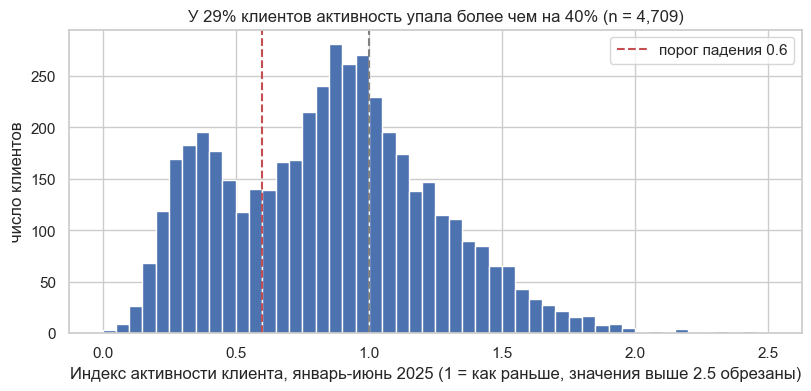

In [45]:
cnt = (ok.pivot_table(index="client_id", columns="month", values="txn_id", aggfunc="count", fill_value=0)
         .reindex(clients_clean.client_id).fillna(0))
m24 = [m for m in cnt.columns if m.year == 2024]
m25 = [m for m in cnt.columns if m.year == 2025]

bank24 = cnt[m24].sum()
season = pd.Series((bank24 / bank24.mean()).values, index=[m.month for m in m24])
H1_SEASON = season.loc[1:6].sum()

activity = pd.DataFrame(index=clients_clean.client_id)
activity["base12"] = cnt[m24].sum(axis=1) / 12
activity["act_all"] = cnt[m25].sum(axis=1)
activity["exp_all"] = activity.base12 * H1_SEASON
for name, months in {"jf": [1, 2], "ma": [3, 4], "mj": [5, 6]}.items():
    activity["act_" + name] = sum(cnt[pd.Period(f"2025-{m:02d}")] for m in months)
    activity["exp_" + name] = activity.base12 * season.loc[months].sum()
activity["ai"] = activity.act_all / activity.exp_all.replace(0, np.nan)
activity["ai_late"] = activity.act_mj / activity.exp_mj.replace(0, np.nan)
MIN_BASE = 2.0
activity["measurable"] = activity.base12 >= MIN_BASE

print("Клиентов с измеримой базой (>= 2 операции в месяц в 2024):", share(int(activity.measurable.sum()), len(activity)))
print("Клиентов без операций в 2024:", int((activity.base12 == 0).sum()), "| из них с операциями в 2025:", int(((activity.base12 == 0) & (activity.act_all > 0)).sum()))

m_ = activity[activity.measurable]
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
ax.hist(m_.ai.clip(0, 2.5), bins=50, color="#4C72B0")
ax.axvline(1, color="grey", ls="--"); ax.axvline(0.6, color="#C44E52", ls="--", label="порог падения 0.6")
ax.set_xlabel("Индекс активности клиента, январь-июнь 2025 (1 = как раньше, значения выше 2.5 обрезаны)"); ax.set_ylabel("число клиентов")
ax.set_title(f"У {(m_.ai <= 0.6).mean():.0%} клиентов активность упала более чем на 40% (n = {len(m_):,})")
ax.legend()
plt.show()

**Какое снижение метрика не видит.**
- Падение размера чека при том же числе операций (рублёвые траты упали сильнее числа операций).
- Клиентов с базой менее 2 операций в месяц в 2024 (916 клиентов, 15,3%): у 407 из них операций в 2024 нет вовсе.
- Уход к другому банку, на наличные или в приложения других банков: данные видят только операции по картам этого банка, причину падения различить нельзя.
- Падение, замаскированное переходом в другой канал, метрика честно не считает падением, но и не отличает «клиент платит телефоном той же картой» от «платит другой картой».

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

In [46]:
DROP = 0.6        # «упала более чем на 40%» от ожидаемого уровня с учётом сезона
FADE = 0.35       # в мае-июне осталось не более 35% ожидаемого: «сошла почти на нет»
MODERATE = 0.75   # умеренное снижение: до 25% ниже ожидаемого и ниже
CAFE_MIN_EXP = 6  # ожидаемых операций в кафе и ресторанах за полугодие, чтобы падение можно было отличить от шума
CAFE_DROP = 0.5   # операций в кафе стало не больше половины ожидаемого
OTHER_OK = 0.8    # остальные траты не ниже 80% ожидаемого
AGE_OLD = 55      # возраст, лет

cafe = ok[ok.category == "Кафе и рестораны"]
cafe24 = cafe[cafe.period == "base"].groupby("client_id").size().reindex(activity.index).fillna(0)
cafe25 = cafe[cafe.period == "eval"].groupby("client_id").size().reindex(activity.index).fillna(0)
activity["cafe_exp"] = cafe24 / 12 * H1_SEASON
activity["cafe_act"] = cafe25
activity["cafe_idx"] = activity.cafe_act / activity.cafe_exp.replace(0, np.nan)
activity["other_idx"] = (activity.act_all - activity.cafe_act) / (activity.exp_all - activity.cafe_exp).replace(0, np.nan)

A = activity.join(clients_clean.set_index("client_id")[["segment", "has_mobile_app", "age", "marketing_opt_in", "loyalty_tier", "city", "card_type"]])
mass, noapp = A.segment == "Массовый", A.has_mobile_app == "Нет"
GROUPS = ["G1 Массовый без приложения: угасание", "G2 Массовый с приложением: глубокое снижение",
          "G3 Массовый без приложения: умеренное снижение", "G4 Премиальный и Private: упали кафе и рестораны",
          "G5 Старше 55 вне массового сегмента: общее снижение"]
rules = {
    GROUPS[0]: A.measurable & mass & noapp & (A.ai_late <= FADE),
    GROUPS[1]: A.measurable & mass & ~noapp & (A.ai <= DROP),
    GROUPS[2]: A.measurable & mass & noapp & (A.ai_late > FADE) & (A.ai <= MODERATE),
    GROUPS[3]: A.measurable & A.segment.isin(["Премиальный", "Private"]) & (A.cafe_exp >= CAFE_MIN_EXP) & (A.cafe_idx <= CAFE_DROP) & (A.other_idx >= OTHER_OK),
    GROUPS[4]: A.measurable & ~mass & (A.age >= AGE_OLD) & (A.ai <= DROP),
}
M = pd.DataFrame(rules)
print("Совпадений с правилами (до выбора группы):", {k.split()[0]: int(v.sum()) for k, v in M.items()})
print("Клиентов, подходящих под несколько правил:", int((M.sum(axis=1) > 1).sum()))
overlap = [(a, b, int((M[a] & M[b]).sum())) for i, a in enumerate(GROUPS) for b in GROUPS[i + 1:] if (M[a] & M[b]).sum() > 0]
print("Пересечения:", [(a.split()[0] + "&" + b.split()[0], n) for a, b, n in overlap])

A["rule_group"] = np.select([M[g] for g in GROUPS], GROUPS, default="")
A["consent"] = A.marketing_opt_in == "Да"
A["group"] = np.where(A.consent & (A.rule_group != ""), A.rule_group, "")
sizes = pd.DataFrame({"правило, клиентов": A[A.rule_group != ""].groupby("rule_group").size(),
                      "без согласия": A[(A.rule_group != "") & ~A.consent].groupby("rule_group").size(),
                      "в кампанию": A[A.group != ""].groupby("group").size()}).reindex(GROUPS).fillna(0).astype(int)
display(sizes)
assert sizes["в кампанию"].min() >= 150, "группа меньше 150"
assert sizes["в кампанию"].sum() <= 2000, "превышен бюджет"
print(f"Итого в кампании: {sizes['в кампанию'].sum():,} клиентов каждый клиент в одной группе:", A[A.group != ""].index.is_unique)

Совпадений с правилами (до выбора группы): {'G1': 418, 'G2': 463, 'G3': 235, 'G4': 179, 'G5': 177}
Клиентов, подходящих под несколько правил: 2
Пересечения: [('G4&G5', 2)]


,"правило, клиентов",без согласия,в кампанию
G1 Массовый без приложения: угасание,418,54,364
G2 Массовый с приложением: глубокое снижение,463,60,403
G3 Массовый без приложения: умеренное снижение,235,33,202
G4 Премиальный и Private: упали кафе и рестораны,179,19,160
G5 Старше 55 вне массового сегмента: общее снижение,175,15,160


Итого в кампании: 1,289 клиентов каждый клиент в одной группе: True


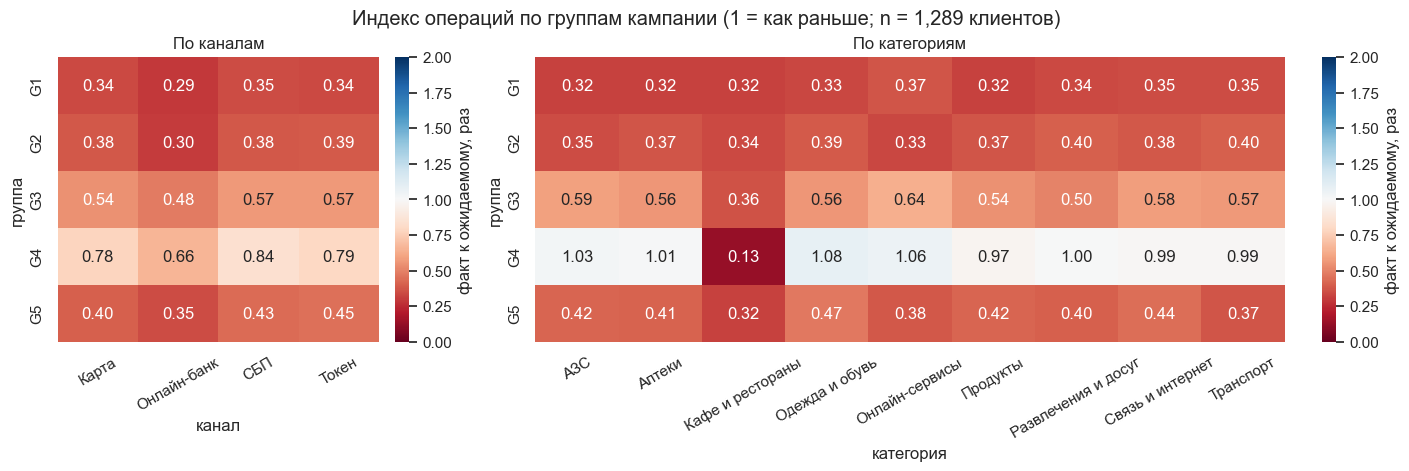

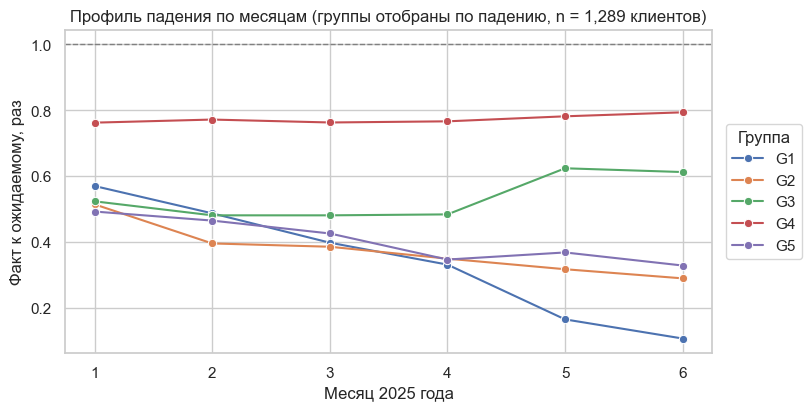

,1,2,3,4,5,6
G1,0.57,0.49,0.40,0.33,0.17,0.11
G2,0.52,0.40,0.39,0.35,0.32,0.29
G3,0.52,0.48,0.48,0.48,0.62,0.61
G4,0.76,0.77,0.76,0.77,0.78,0.79
G5,0.49,0.47,0.43,0.35,0.37,0.33


In [47]:
def expected_actual(dim):
    b = ok[ok.period == "base"].pivot_table(index="client_id", columns=dim, values="txn_id", aggfunc="count", fill_value=0).reindex(activity.index).fillna(0)
    e = ok[ok.period == "eval"].pivot_table(index="client_id", columns=dim, values="txn_id", aggfunc="count", fill_value=0).reindex(activity.index).fillna(0)
    return b / 12 * H1_SEASON, e

comp = {}
for dim in ["channel", "category"]:
    expd, act = expected_actual(dim)
    rows = {}
    for g in GROUPS:
        ids = A.index[A.group == g]
        rows[g] = (act.loc[ids].sum() / expd.loc[ids].sum()).round(2)
    comp[dim] = pd.DataFrame(rows).T

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained", gridspec_kw={"width_ratios": [0.6, 1.4]})
for ax, dim, title in [(axes[0], "channel", "По каналам"), (axes[1], "category", "По категориям")]:
    t = comp[dim].copy(); t.index = [g.split()[0] for g in t.index]
    sns.heatmap(t, annot=True, fmt=".2f", cmap="RdBu", center=1, vmin=0, vmax=2, ax=ax, cbar_kws={"label": "факт к ожидаемому, раз"})
    ax.set_xlabel(dim.replace("channel", "канал").replace("category", "категория")); ax.set_ylabel("группа"); ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
fig.suptitle(f"Индекс операций по группам кампании (1 = как раньше; n = {int((A.group != '').sum()):,} клиентов)")
plt.show()

prof = {}
for g in GROUPS:
    ids = A.index[A.group == g]
    prof[g.split()[0]] = [cnt.loc[ids, pd.Period(f"2025-{m:02d}")].sum() / (A.loc[ids, "base12"].sum() * season.loc[m]) for m in range(1, 7)]
prof = pd.DataFrame(prof, index=range(1, 7))
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
sns.lineplot(data=prof, dashes=False, marker="o", ax=ax)
ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("Месяц 2025 года"); ax.set_ylabel("Факт к ожидаемому, раз")
ax.set_title(f"Профиль падения по месяцам (группы отобраны по падению, n = {int((A.group != '').sum()):,} клиентов)")
ax.legend(title="Группа", loc="center left", bbox_to_anchor=(1.01, 0.5)); plt.show()
display(prof.round(2).T)

In [49]:
campaign = A[A.group != ""].reset_index()[["client_id", "group"]]
assert campaign.client_id.is_unique and len(campaign) <= 2000
assert campaign.group.value_counts().min() >= 150
assert (clients_clean.set_index("client_id").loc[campaign.client_id, "marketing_opt_in"] == "Да").all(), "есть клиент без согласия"
print("Строк в campaign_list:", len(campaign), "| групп:", campaign.group.nunique())
display(campaign.group.value_counts().rename("клиентов").to_frame())

Строк в campaign_list: 1289 | групп: 5


,клиентов
group,
G2 Массовый с приложением: глубокое снижение,403
G1 Массовый без приложения: угасание,364
G3 Массовый без приложения: умеренное снижение,202
G5 Старше 55 вне массового сегмента: общее снижение,160
G4 Премиальный и Private: упали кафе и рестораны,160


**Группы для кампании.** Каждая группа описана правилом из двух частей: кто этот клиент и что с ним произошло (порог величины падения только уточняет правило). Группы взаимоисключающие: пересекаются только G4 и G5 (2 клиента), приоритет у G4, потому что причина конкретнее. В список попадают только клиенты с согласием на коммуникацию.

| Группа | Кто | Что произошло | За счёт чего упало | Клиентов | Доля недобора банка
|---|---|---|---|---|---|
| G1 | массовый сегмент, нет приложения | активность сошла почти на нет: в мае-июне не более 35% ожидаемого (медиана 0,12), месячный индекс 0,57 → 0,11 | по всем каналам и категориям поровну (0,29-0,37), чуть сильнее онлайн-банк | 364 | 18,0% |
| G2 | массовый сегмент, есть приложение | глубокое снижение: индекс ≤ 0,6 (медиана 0,37), растёт вниз с января (0,52 → 0,29) | по всем каналам и категориям (0,33-0,40), токен не компенсирует (0,39) | 403 | 20,7% |
| G3 | массовый сегмент, нет приложения | умеренное снижение: индекс до 0,75 (медиана 0,54), но не до нуля в мае-июне | в целом по всем (0,5-0,6), сильнее всего просели кафе и рестораны (0,36) | 202 | 6,8% |
| G4 | премиальный и Private | траты в кафе и ресторанах упали минимум вдвое (индекс по группе 0,13), остальные траты на уровне прошлого (0,97-1,08) | почти целиком кафе и рестораны | 160 | 4,5% |
| G5 | не массовый сегмент, 55 лет и старше | общее снижение: индекс ≤ 0,6 (медиана 0,42), 0,49 → 0,33 | по всем каналам и категориям (0,32-0,47) | 160 | 8,2% |

### 7.1. Кого в кампанию не берём и почему

In [50]:
n_all = len(clients_clean) + len(ids_conf) + n_orphan_ids
rule_any = A.rule_group != ""
not_incl = pd.Series({
    "Нет в справочнике действующих (есть только в операциях)": n_orphan_ids,
    "Конфликт атрибутов в справочнике (город/сегмент неоднозначны)": len(ids_conf),
    "Нет операций в 2024 (в основном новая карта 2025), падение не измерить": int((A.base12 == 0).sum()),
    "Мало истории: меньше 2 операций в месяц в 2024 (но не ноль), падение не отличить от шума": int(((A.base12 > 0) & ~A.measurable).sum()),
    "Подходят под правило, но нет согласия на коммуникацию": int((rule_any & ~A.consent).sum()),
})
rest = A[A.measurable & ~rule_any]
rest_cat = np.select(
    [rest.ai >= 0.9, rest.ai > DROP], ["Активность не снизилась (индекс 0.9 и выше)", "Умеренное снижение (индекс 0.6-0.9), в рамках обычных колебаний"],
    default="Падение, но не подошло ни под одно правило группы")
rest_s = pd.Series(rest_cat).value_counts()
excl = pd.concat([not_incl, rest_s]); excl.loc["Включены в кампанию"] = int((A.group != "").sum())
tbl = excl.rename("клиентов").to_frame(); tbl["доля, %"] = (tbl["клиентов"] / n_all * 100).round(1)
display(tbl)
assert int(tbl["клиентов"].sum()) == n_all, f"баланс не сходится: {int(tbl['клиентов'].sum())} против {n_all}"
print(f"Знаменатель: {n_all:,}")

exp_ch, act_ch = expected_actual("channel")
swap = (A.measurable & (A.ai >= 0.9) & ((act_ch["Карта"] / exp_ch["Карта"].replace(0, np.nan)) <= 0.8) & ((act_ch["Токен"] / exp_ch["Токен"].replace(0, np.nan)) >= 1.2))
new_card = clients_clean.set_index("client_id").loc[A.index[A.base12 == 0], "card_open_date"] >= "2025-01-01"
print("Клиентов без операций в 2024:", int((A.base12 == 0).sum()), "| из них карта открыта в 2025:", share(int(new_card.sum()), len(new_card)))
print("Клиентов, у которых карта упала, токен вырос, а общая активность не снизилась:", share(int(swap.sum()), int(A.measurable.sum())), "из измеримых")
log("client_id", "клиенты без согласия на маркетинг исключены из групп", "client_id вне campaign_list", int((~A.consent & rule_any).sum()),
    "подходят под правило группы", "исключено из кампании", "не попадают в campaign_list",
    "коммуникация возможна только при согласии клиента; без согласия клиент остаётся в аналитике, но не в списке рассылки")

,клиентов,"доля, %"
Нет в справочнике действующих (есть только в операциях),361,6.0
Конфликт атрибутов в справочнике (город/сегмент неоднозначны),14,0.2
"Нет операций в 2024 (в основном новая карта 2025), падение не измерить",407,6.8
"Мало истории: меньше 2 операций в месяц в 2024 (но не ноль), падение не отличить от шума",509,8.5
"Подходят под правило, но нет согласия на коммуникацию",181,3.0
Активность не снизилась (индекс 0.9 и выше),2110,35.2
"Умеренное снижение (индекс 0.6-0.9), в рамках обычных колебаний",971,16.2
"Падение, но не подошло ни под одно правило группы",158,2.6
Включены в кампанию,1289,21.5


Знаменатель: 6,000
Клиентов без операций в 2024: 407 | из них карта открыта в 2025: 347 из 407 (85.26%)
Клиентов, у которых карта упала, токен вырос, а общая активность не снизилась: 355 из 4,709 (7.54%) из измеримых


**Кого не включаем (баланс по 6 000 клиентам из двух выгрузок).**
- **361 клиент (6,0%) вне справочника действующих**: есть только в операциях, их операции исчезают к апрелю 2025 (вероятно, ушли из банка; данными не подтверждено); нет сегмента, возраста и согласия на коммуникацию.
- **14 клиентов (0,2%) с конфликтом атрибутов** (две версии города или сегмента): правило группы к ним неприменимо.
- **407 клиентов (6,8%) без операций в 2024**: падение измерить нельзя; у 85% из них карта открыта в 2025 (новая карта), это другая задача (первое использование).
- **509 клиентов (8,5%) с базой меньше 2 операций в месяц**: падение не отличить от шума.
- **181 клиент (3,0%) подходит под правило, но без согласия** на коммуникацию (G1 54, G2 60, G3 33, G4 19, G5 15).
- **2 110 клиентов (35,2%)**: активность не снизилась (индекс 0,9 и выше); **971 клиент (16,2%)** с умеренным снижением 0,6-0,9: это в пределах обычных колебаний; **158 клиентов (2,6%)** с падением, но не подошли ни под одно правило.
- Отдельно: у 355 клиентов (7,5% измеримых) карта упала, а токен вырос и общая активность не снизилась. Это не снижение активности, поэтому в кампанию они не идут.

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [51]:
rows = []
city_mass = A[A.segment == "Массовый"].groupby("city").ai.median()
nn = clients_clean[clients_clean.city == "Нижний Новгород"]
rows.append(("Нижний Новгород падает сильнее остальных городов",
             f"операции 2025 к 2024: Н. Новгород {h1_ratio_by('city').set_index('значение').loc['Нижний Новгород', 'операции 2025 к 2024, раз']:.2f}; доля массовых там {(nn.segment == 'Массовый').mean():.0%}",
             f"внутри массового сегмента индекс активности (медиана) в Н. Новгороде {city_mass['Нижний Новгород']:.2f} против {city_mass.drop('Нижний Новгород').min():.2f}-{city_mass.drop('Нижний Новгород').max():.2f} в других городах",
             "Не подтвердилось: разница объясняется составом клиентов (парадокс Симпсона), а не городом"))
al = clients_clean.set_index("client_id").app_last_login
lag = ((pd.Period("2025-06", "M").ordinal) - al.dropna().dt.to_period("M").map(lambda p: p.ordinal))
mm_ = A.loc[lag.index].assign(lag=lag)
mm_ = mm_[mm_.measurable & (mm_.segment == "Массовый")]
lb = pd.cut(mm_.lag, [-1, 3, 12, 100], labels=["до 3 мес.", "3-12 мес.", "больше года"])
r_lag = mm_.groupby(lb, observed=True).ai.median()
rows.append(("Те, кто давно не заходил в приложение, падают сильнее (массовый сегмент с приложением)",
             f"индекс активности (медиана) по давности входа: " + ", ".join(f"{k} {v:.2f}" for k, v in r_lag.items()),
             f"n = {len(mm_):,} клиентов", "Не подтвердилось: связи с давностью входа нет"))
sat = A.join(clients_clean.set_index("client_id").satisfaction_score)
sat = sat[sat.measurable & (sat.segment == "Массовый") & sat.satisfaction_score.notna()]
r_sat = sat.groupby("satisfaction_score").ai.median()
rows.append(("Недовольные клиенты падают сильнее",
             f"индекс активности (медиана) по оценкам 1-5: " + ", ".join(f"{int(k)}: {v:.2f} (n={n})" for (k, v), n in zip(r_sat.items(), sat.groupby("satisfaction_score").size())),
             f"массовый сегмент, n = {len(sat):,} клиентов с оценкой", "Слабо: клиенты с оценкой 1 чуть ниже, но их мало, а оценка есть не у всех; основания для группы недостаточно"))
rows.append(("Сравнение 2025 со средним месяцем 2024 показывает реальное падение",
             f"в лоб {naive:+.1%}, те же месяцы {like:+.1%}", f"декабрь 2024 = {cal.loc[12, '2024'] / cal['2024'].mean():.2f} от среднего месяца",
             "Подтвердилось частично: часть падения - сезонность, поэтому метрика учитывает сезон"))
res8 = pd.DataFrame(rows, columns=["гипотеза", "проверка", "число", "вывод"])
pd.set_option("display.max_colwidth", 140)
display(res8)

,гипотеза,проверка,число,вывод
0,Нижний Новгород падает сильнее остальных городов,операции 2025 к 2024: Н. Новгород 0.78; доля массовых там 87%,внутри массового сегмента индекс активности (медиана) в Н. Новгороде 0.75 против 0.72-0.80 в других городах,"Не подтвердилось: разница объясняется составом клиентов (парадокс Симпсона), а не городом"
1,"Те, кто давно не заходил в приложение, падают сильнее (массовый сегмент с приложением)","индекс активности (медиана) по давности входа: до 3 мес. 0.83, 3-12 мес. 0.83, больше года 0.84","n = 1,455 клиентов",Не подтвердилось: связи с давностью входа нет
2,Недовольные клиенты падают сильнее,"индекс активности (медиана) по оценкам 1-5: 1: 0.63 (n=136), 2: 0.75 (n=174), 3: 0.70 (n=163), 4: 0.78 (n=163), 5: 0.78 (n=192)","массовый сегмент, n = 828 клиентов с оценкой","Слабо: клиенты с оценкой 1 чуть ниже, но их мало, а оценка есть не у всех; основания для группы недостаточно"
3,Сравнение 2025 со средним месяцем 2024 показывает реальное падение,"в лоб -17.2%, те же месяцы -10.2%",декабрь 2024 = 1.29 от среднего месяца,"Подтвердилось частично: часть падения - сезонность, поэтому метрика учитывает сезон"


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [53]:
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")


tx_save = tx_clean.assign(month=tx_clean.month.astype(str))
try:
    clients_clean.to_parquet("clients_clean.parquet", index=False); tx_save.to_parquet("tx_clean.parquet", index=False)
    fmt = "parquet"
except ImportError:
    clients_clean.to_csv("clients_clean.csv.gz", index=False, encoding="utf-8"); tx_save.to_csv("tx_clean.csv.gz", index=False, encoding="utf-8")
    fmt = "csv.gz (pyarrow не установлен)"

A.reset_index().to_csv("client_metrics.csv", index=False, encoding="utf-8")
print("Сохранено: cleaning_log.csv (%d решений), campaign_list.csv (%d клиентов), clients_clean и tx_clean в формате %s, client_metrics.csv, group_summary.csv"
      % (len(cleaning_log), len(campaign), fmt))

Сохранено: cleaning_log.csv (26 решений), campaign_list.csv (1289 клиентов), clients_clean и tx_clean в формате parquet, client_metrics.csv, group_summary.csv
